# Peripheral wall choice: a geometric race model

Central models beat peripheral models in every tournament so far. Human peripheral players, by contrast, score at about the same rate as human central players. This notebook asks how much of that could come from wall choice alone, using only arena geometry.

**Question.** A peripheral agent races a central agent that waits at the centre and always goes High. How do both agents' score rates change if the peripheral agent follows each of these rules?
1. Always move to the High wall.
2. Always move to the closest lit wall.
3. Move to High, unless High takes more than Δ seconds longer to reach than Low. Then move to the closest wall.

**Plan**
1. Inputs from the logs (speed, and the fixed time per trial outside the race).
2. Peripheral slice-onset positions.
3. Travel times to High and Low from those positions, against the central agent's.
4. Score rate as the threshold Δ changes.
5. The three rules side by side, including the margin over the opponent.
6. The three rules for each set of peripheral start positions.
7. How central agents turn to face High in the logs. These are the inputs for the ray-sensing model.
8. The ray-sensing model: the peripheral agent's design.
9. The ray-sensing model: three peripheral rules compared against the central agent.
10. Why taking the closest wall goes from slightly ahead to well behind once walls must be found.
11. Inference: choosing the search direction from where High probably is.
12. The Δ rule with inference about both walls: go for Low when High is (probably) much further.
13. Where the score comes from: which layouts each agent wins, and how.

Sections 3-6 use the first version of the model, where both agents know both lit walls at onset. Sections 8-9 use the ray-sensing version, where both agents sense walls with the agents' 7 rays.

**Choices and assumptions**
- Geometry only (user's choice). Each agent's time to a wall is its shortest path to the wall's trigger divided by the speed. No start-up delay and no timing noise, as neither is justified by geometry.
- Visibility of walls and of the opponent is ignored for now. Both agents know both lit walls at slice onset (user's choice, to be added later).
- The central agent waits at the exact centre and always goes High. Its behaviour never changes: only the peripheral agent's rule (and its threshold Δ) varies. The central agent's *score* still changes with the peripheral rule, because it depends on how many races the central agent wins. The fixed reference is central-vs-central play. 260929 central models took High on 0.998 of 5,344 won trials, and on 0.975 even when Low was more than 6 units nearer (checked 2026-10-19). This does not test lost trials, where the destination is not logged.
- Peripheral positions are the logged slice-onset positions of the 260929 peripheral models (mean onset centrality below 0.5). Each position meets all 40 layouts.
- Layouts follow `OctagonArenaSettings.cs`. High is uniform over the 8 walls. Low is 1, 2 or 4 walls away (weights 0.5/0.25/0.25) on a random side.
- An agent whose body overlaps a lit trigger at slice onset wins that wall at once, whatever its rule (game rule).
- Neither agent blocks the other. Equal travel times split the win.
- Score per second is the primary measure (players are told to maximise score over time). It is total expected score over total expected trial time. Trial time is the race plus the fixed time per trial outside it (trial start to slice onset, trigger to trial end, and the ITI). Score per trial is secondary.
- Relative score is also reported (user's choice). It is the peripheral agent's score per second minus its opponent's. Human players may try to beat the other player as well as to maximise their own score. A central player facing a central opponent ties every race, so its margin is 0.
- Trials follow the repo convention (first logged trial dropped, incomplete final trial dropped). Agent sims have no spawn trial at the arena centre.

**Modules.** All numbers come from `analysis/analytical_race.py`. The geometry and the race scoring are checked against hand-counted answers in `tests/test_analytical_race.py` (20 tests). For example, from the eight alcove backs, "always High" wins 7/16 of trials and scores 0.3625 per trial, and "closest" scores 0.425. Decisions are logged in `READMEs/analytical_modelling_notes.md`.

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import data_strings
import data_extraction.data_saving as data_saving
import analysis.analytical_race as ar

RECOMPUTE = False                   # rebuild the cached tables
BATCH = '260929'
SIM_DATA_FOLDER = os.path.join(data_strings.SIM_DATA_FOLDER, '2609', BATCH)
CUT = 0.5                           # peripheral below this mean onset centrality
DELTAS = np.round(np.arange(0, 3.81, 0.05), 2)     # thresholds swept (s); 3.8 s is the longest gap possible

# colours: peripheral agent and its rules in fixed order, central agent in grey
C_HIGH, C_CLOSEST, C_THRESH, C_CENTRAL = '#2a78d6', '#eb6834', '#1baf7a', '#6b6b6b'
C_PERIPH = C_HIGH

# soft presentation style (as in geometric_model_assembly.ipynb), used for figures meant for slides
SOFT = {'font.family': 'Liberation Sans', 'axes.edgecolor': '#a0a0a0', 'axes.linewidth': 1.3, 'text.color': '#3a3a3a',
        'axes.labelcolor': '#444444', 'xtick.color': '#666666', 'ytick.color': '#666666', 'axes.spines.top': False,
        'axes.spines.right': False, 'legend.frameon': False}
SOFT_PERIPH, SOFT_WALL, SOFT_CENTRAL, SOFT_INK = '#5b8db8', '#c4c4c4', '#9a9a9a', '#3a3a3a'


def presentation_text(fig, base=18, inner=None):
    """ Set large text and heavier axes on a figure for slides: titles base+4, axis labels base+2,
        everything else base. White text is set to inner (default base-4). Takes the figure, the base
        size and the size for white text. """

    inner = base - 4 if inner is None else inner
    for ax in fig.axes:
        ax.title.set_fontsize(base + 4)
        ax.xaxis.label.set_size(base + 2); ax.yaxis.label.set_size(base + 2)
        ax.tick_params(labelsize=base, width=2, length=7)
        for sp_ in ax.spines.values():
            sp_.set_linewidth(2)
        for t in ax.texts:
            t.set_fontsize(inner if t.get_color() in ('white', '#ffffff') else base)
        leg = ax.get_legend()
        if leg is not None:
            for t in leg.get_texts():
                t.set_fontsize(base)

## 1. Inputs from the logs

**Motivation.** The model needs two numbers from the game: how fast an agent moves, and how much time each trial costs outside the race. The speed is measured from 260929 self-play, and the time outside the race from the human social sessions.

**Method.** For five central models, take each trial's median moving speed (both agents, slice onset to trigger, frames moving faster than 0.5 units/s) and its overhead. For the human social sessions, take each trial's overhead as the sum of its start delay, end delay and ITI (`ar.human_trial_delays`).

**Terms**
- Moving speed in units/s. The code sets `moveSpeed` to 10.
- Overhead is the time per trial outside the race, in seconds. It covers trial start to slice onset (uniform 0.5-1.5 s in the game settings), trigger to trial end (fixed 2 s) and the ITI (uniform 2-5 s), so its expected mean is 6.5 s. For agents, `overhead_s` is the whole trial length less the slice-onset-to-trigger time.

**Choices.**
- The human social mean overhead is used for every trial, whatever the outcome (user's choice, as human play is the endpoint). Only the mean enters score per second (total score over total time).
- The agent overhead is not used. The agent simulation rounds each delay up to a 1/3 s frame, which adds about 0.6 s per trial (`geometric_model_assembly.ipynb`, section 1).

**How to read the figure.** Left: one count per trial, the trial's median moving speed; the dashed line is the model speed. Right: the share of trials at each overhead, for human social trials (filled) and agent trials (outline). The dashed line is the human mean, used in the model; the dotted line is the agent mean.

**Why it is plotted.** The speed should sit at 10 in every trial, so that path length converts directly to time. The overhead panel shows the spread around the mean, and the shift of the agent trials above the human ones.

trial_timing_260929_central5: loaded from cache
human_trial_delays: loaded from cache
human_trial_delays: loaded from cache


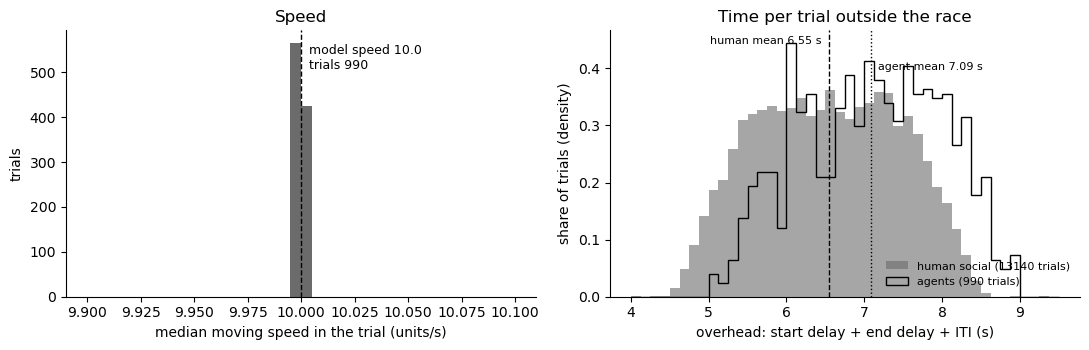

In [2]:
# split the batch by mean onset centrality
tables = data_saving.load_data(f'model_characterisation_{BATCH}', data_saving.cache_dir)['result']
centrality = tables['slice'].groupby('model')['centrality'].mean()
PERIPHERAL = sorted(centrality[centrality < CUT].index)
CENTRAL = sorted(centrality[centrality >= CUT].index)

# get per-trial speed and overhead for five central models
timing_df = data_saving.cached(f'trial_timing_{BATCH}_central5',
                               lambda: ar.collect_trial_timing(SIM_DATA_FOLDER, CENTRAL[:5], verbose=False),
                               recompute=RECOMPUTE, stamp=(tuple(CENTRAL[:5]), 'v2'))
AGENT_OVERHEAD = timing_df['overhead_s'].mean()
# get the human social overhead per trial, whose mean is used in the model
human_delays = ar.human_trial_delays(recompute=RECOMPUTE)
human_over = human_delays.loc[human_delays['session type'] == 'social', list(ar.DELAY_PARTS)].sum(axis=1)
OVERHEAD = ar.human_overhead('social')

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
ax.hist(timing_df['speed_median'], bins=np.linspace(9.9, 10.1, 41), color=C_CENTRAL)
ax.axvline(ar.SPEED, color='black', ls='--', lw=1)
ax.text(ar.SPEED, ax.get_ylim()[1] * 0.95, f"  model speed {ar.SPEED:.1f}\n  trials {len(timing_df)}", va='top', fontsize=9)
ax.set_xlabel('median moving speed in the trial (units/s)')
ax.set_ylabel('trials')
ax.set_title('Speed')
ax = axes[1]
bins = np.linspace(4, 9.5, 45)
ax.hist(human_over, bins=bins, density=True, color=C_CENTRAL, alpha=0.6, label=f'human social ({len(human_over)} trials)')
ax.hist(timing_df['overhead_s'], bins=bins, density=True, histtype='step', color='black', lw=1.2,
        label=f'agents ({len(timing_df)} trials)')
ax.axvline(OVERHEAD, color='black', ls='--', lw=1)
ax.axvline(AGENT_OVERHEAD, color='black', ls=':', lw=1)
ax.text(OVERHEAD, ax.get_ylim()[1] * 0.98, f"human mean {OVERHEAD:.2f} s  ", ha='right', va='top', fontsize=8)
ax.text(AGENT_OVERHEAD, ax.get_ylim()[1] * 0.88, f"  agent mean {AGENT_OVERHEAD:.2f} s", va='top', fontsize=8)
ax.set_xlabel('overhead: start delay + end delay + ITI (s)')
ax.set_ylabel('share of trials (density)')
ax.legend(frameon=False, fontsize=8, loc='lower right')
ax.set_title('Time per trial outside the race')
for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

## 2. Peripheral slice-onset positions

**Motivation.** A peripheral agent's start position decides every travel time in the model. This section shows where the peripheral models actually wait.

**Method.** Take both agents' slice-onset positions on every trial of each peripheral model (first logged trial dropped).

**Terms**
- Onset radius is the distance from the arena centre in units. The alcove back is at 19.75 and the wall face at 16.75.
- The trigger line (18.25) is where an agent's body first overlaps a trigger box. An agent beyond it, inside a lit alcove, wins at once.

**How to read the figure.** Left: the reachable space (grey outline), one dot per agent-trial at slice onset (blue, semi-transparent), and the central agent's fixed start (black). Right: the onset radius of the same positions, with the trigger line, wall face and alcove back marked in the panel.

**Why it is plotted.** Positions past the trigger line can win their own alcove instantly. Positions short of it, such as the alcove mouth, have to move even to reach their own wall. That changes which rule is best.

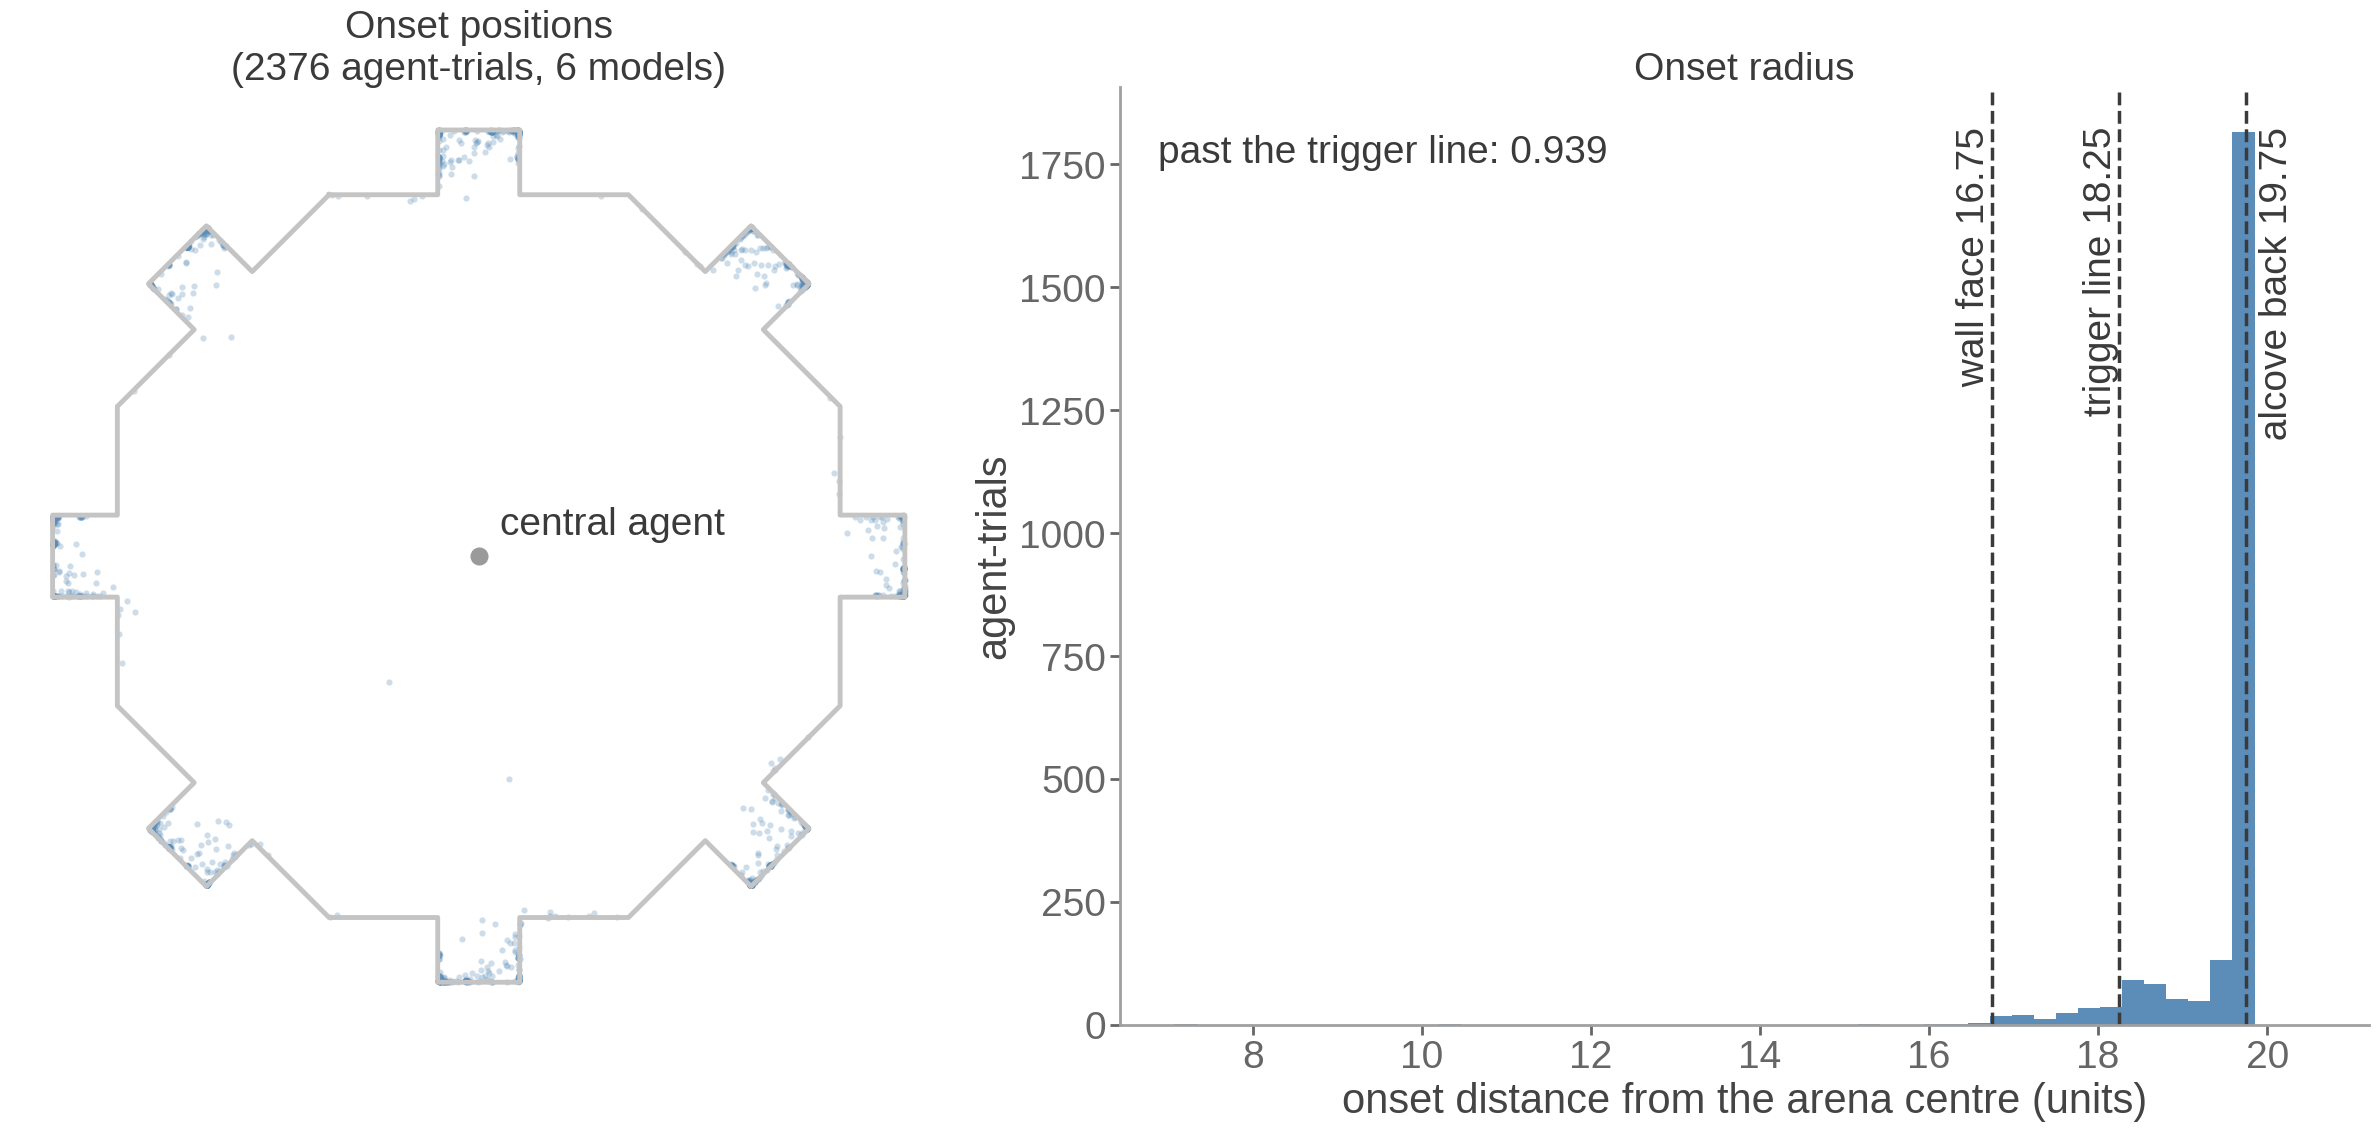

In [3]:
# get the peripheral onset positions from the race table (both agents, first trial already dropped)
race_df = data_saving.load_data(f'race_table_{BATCH}', data_saving.cache_dir)['result']
periph = race_df[race_df['model'].isin(PERIPHERAL)].reset_index(drop=True)
pos = periph[['x', 'z']].to_numpy(float)
radius = np.hypot(pos[:, 0], pos[:, 1])

with plt.rc_context(SOFT):
    fig, axes = plt.subplots(1, 2, figsize=(24, 11), gridspec_kw=dict(width_ratios=[1, 1.3]))
    ax = axes[0]
    poly = np.vstack([ar.reach_polygon(), ar.reach_polygon()[:1]])
    ax.plot(poly[:, 0], poly[:, 1], color=SOFT_WALL, lw=3.5)
    ax.scatter(pos[:, 0], pos[:, 1], s=20, color=SOFT_PERIPH, alpha=0.3, lw=0)
    ax.plot(0, 0, 'o', color=SOFT_CENTRAL, ms=12)
    ax.text(1.0, 1.0, 'central agent', fontsize=9)
    ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([]); ax.axis('off')
    ax.set_title(f'Onset positions\n({len(pos)} agent-trials, 6 models)', fontsize=10)
    ax = axes[1]
    ax.hist(radius, bins=np.linspace(radius.min() - 0.1, 19.85, 50), color=SOFT_PERIPH)
    for r, lab, side in ((ar.W, 'wall face', 'right'), (ar.TRIGGER_REACH, 'trigger line', 'right'), (ar.BACK, 'alcove back', 'left')):
        ax.axvline(r, color=SOFT_INK, ls='--', lw=2.5)
        ax.text(r + (0.15 if side == 'left' else 0.0), ax.get_ylim()[1] * 0.97, f' {lab} {r:.2f} ', rotation=90, va='top', ha=side, fontsize=8)
    ax.set_xlim(right=21.2)
    past = (radius >= ar.TRIGGER_REACH).mean()
    ax.text(0.03, 0.95, f"past the trigger line: {past:.3f}", transform=ax.transAxes, va='top', fontsize=9)
    ax.set_xlabel('onset distance from the arena centre (units)')
    ax.set_ylabel('agent-trials')
    ax.set_title('Onset radius')
    presentation_text(fig, base=28)
    for ax_ in axes:
        ax_.title.set_fontsize(28)
    plt.tight_layout(); plt.show()

## 3. Travel times to High and Low

**Motivation.** A rule can only change the outcome where the walls differ in whether they can be reached first. This section shows how often each case occurs.

**Method.** Pair every peripheral position with all 40 layouts. Take the peripheral agent's travel time to High and to Low, and the central agent's travel time to High. Weight each pair by its layout probability, with every position counting equally.

**Terms**
- `t_high`, `t_low`: peripheral shortest path to that wall's trigger / 10 units/s, in seconds. 0 = already on the trigger.
- Central time: 18.25 / 10 = 1.82 s to any wall, from the centre.
- A wall is winnable when the peripheral time to it is below the central time.

**How to read the figure.** Each cell is a combination of peripheral time to High (x) and to Low (y). Shading is the probability of that combination (darker = more likely, log scale). The dashed lines mark the central agent's time, splitting the panel into four regions. The label in each region gives its total probability. The dotted diagonal marks equal times.

**Why it is plotted.** "Only Low winnable" (bottom right) is where heading Low adds score that "always High" misses. "Both winnable" is where heading Low throws away a High win. All three rules agree in "neither winnable" and "only High winnable", unless the rule sends the agent to a losing Low.

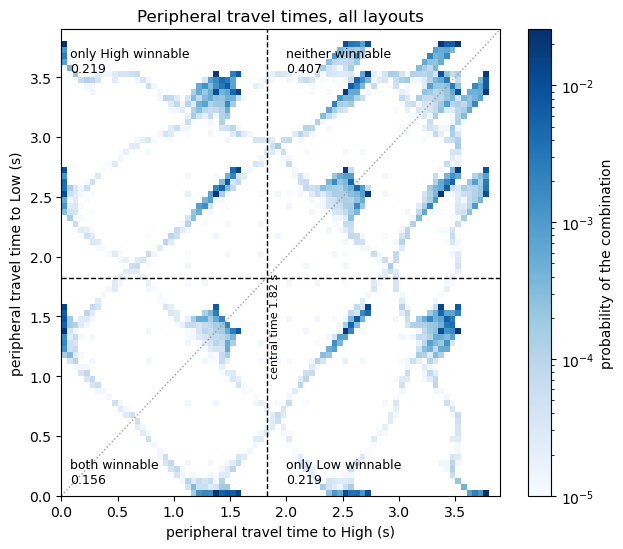

In [4]:
# build the races once per model (each model weighs its own positions equally) and pooled (every position equal)
races = ar.build_races(pos, groups=periph['model'].to_numpy())
pooled = races.assign(group=0, prob=races['prob'] * races.groupby('group')['pos'].transform('nunique') / len(pos))
w = pooled['prob'].to_numpy()
tC = ar.TRIGGER_REACH / ar.SPEED
tH, tL = races['t_high'].to_numpy(), races['t_low'].to_numpy()
regions = {'both winnable': (tH < tC) & (tL < tC), 'only High winnable': (tH < tC) & (tL >= tC),
           'only Low winnable': (tH >= tC) & (tL < tC), 'neither winnable': (tH >= tC) & (tL >= tC)}
share = {k: w[m].sum() for k, m in regions.items()}

fig, ax = plt.subplots(figsize=(6.4, 5.6))
bins = np.linspace(0, 3.9, 79)
h, xe, ye = np.histogram2d(tH, tL, bins=[bins, bins], weights=w)
im = ax.pcolormesh(xe, ye, np.ma.masked_equal(h.T, 0), cmap='Blues',
                   norm=plt.matplotlib.colors.LogNorm(vmin=1e-5, vmax=h.max()))
ax.axvline(tC, color='black', ls='--', lw=1); ax.axhline(tC, color='black', ls='--', lw=1)
ax.plot([0, 3.9], [0, 3.9], color='#999999', ls=':', lw=1)
for k, (x, y) in {'both winnable': (0.08, 0.08), 'only High winnable': (0.08, 3.75),
                  'only Low winnable': (2.0, 0.08), 'neither winnable': (2.0, 3.75)}.items():
    ax.text(x, y, f"{k}\n{share[k]:.3f}", va='bottom' if y < 1 else 'top', fontsize=9)
ax.text(tC + 0.03, 1.0, f'central time {tC:.2f} s', rotation=90, fontsize=8)
ax.set_xlabel('peripheral travel time to High (s)')
ax.set_ylabel('peripheral travel time to Low (s)')
ax.set_title('Peripheral travel times, all layouts')
fig.colorbar(im, ax=ax, label='probability of the combination')
plt.tight_layout(); plt.show()

## 4. Score rate as the threshold changes

**Motivation.** Rule 3 depends on its threshold Δ. Sweeping Δ shows which values work best, and how the rule moves between "closest" and "always High".

**Method.** For Δ from 0 to 3.8 s (step 0.05), apply rule 3 to every position and layout, and compute both agents' expected scores.

**Terms**
- Δ: the extra travel time to High (over Low) at which the peripheral agent gives up on High, in seconds. Δ belongs to the peripheral rule only. The central agent goes High from the centre (1.82 s) at every Δ. Δ = 0 is "closest". Δ ≥ 3.8 s is "always High", as no gap is longer.
- Score per second: total expected score / total expected trial time, with trial time = race + overhead.
- Share heading Low: fraction of trials in which the rule sends the agent to Low. Instant wins count by the rule's choice.
- Central score: the central agent's behaviour is fixed, so its score moves only because the peripheral agent wins more or fewer races. Per trial it equals 1 − the peripheral win share (every central win is at High). Per second it also shifts slightly with race length.
- Central vs central: both agents at the centre going High, so every race ties (0.5 per trial). It does not depend on Δ, and is the fixed reference for a central player.

**How to read the figure.** x is Δ in all panels. Left: score per second for the peripheral agent (blue) and the central agent (grey). The grey line moves only because the peripheral rule changes who wins; central behaviour is the same at every Δ. The dashed line is central vs central (both at the centre, every race tied), the fixed reference. Middle: the same for score per trial. Right: the share of trials in which the peripheral agent heads for Low. The dotted vertical line marks the Δ with the highest peripheral score per second, labelled in the panel.

**Why it is plotted.** Steps in the curves happen where Δ passes the time gap of a common layout. A wide flat top means the exact threshold matters little.

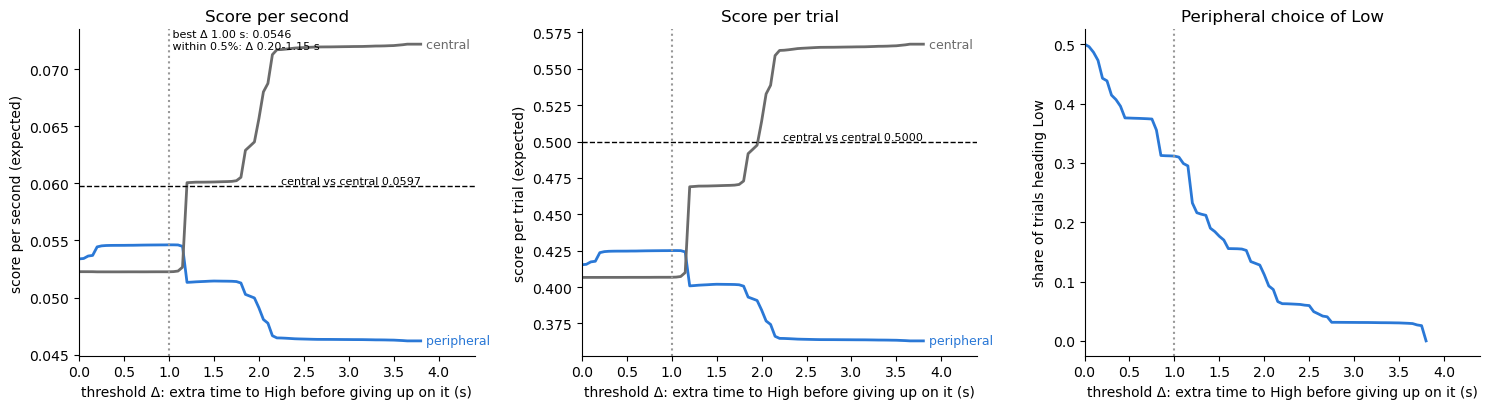

In [5]:
sweep = pd.concat([ar.summarise(pooled, OVERHEAD, 'threshold', d) for d in DELTAS], ignore_index=True)
best = sweep.iloc[sweep['periph_score_s'].to_numpy().argmax()]
D_BEST = float(best['delta'])
# find the flat top (within 0.5% of the best peripheral score per second)
top = sweep.loc[sweep['periph_score_s'] >= 0.995 * best['periph_score_s'], 'delta']
ref = ar.central_reference(OVERHEAD)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (p, c, ylab, r) in zip(axes[:2], (('periph_score_s', 'central_score_s', 'score per second', ref['score_s']),
                                         ('periph_score_trial', 'central_score_trial', 'score per trial', ref['score_trial']))):
    ax.plot(sweep['delta'], sweep[p], color=C_PERIPH, lw=2)
    ax.plot(sweep['delta'], sweep[c], color=C_CENTRAL, lw=2)
    ax.axhline(r, color='black', ls='--', lw=1)
    ax.text(3.8, r, f'central vs central {r:.4f}', ha='right', va='bottom', fontsize=8)
    ax.text(3.82, sweep[p].iloc[-1], ' peripheral', va='center', fontsize=9, color=C_PERIPH)
    ax.text(3.82, sweep[c].iloc[-1], ' central', va='center', fontsize=9, color=C_CENTRAL)
    ax.set_ylabel(f'{ylab} (expected)')
ax = axes[2]
ax.plot(sweep['delta'], sweep['p_go_low'], color=C_PERIPH, lw=2)
ax.set_ylabel('share of trials heading Low')
for ax in axes:
    ax.axvline(D_BEST, color='#999999', ls=':', lw=1.5)
    ax.set_xlabel('threshold Δ: extra time to High before giving up on it (s)')
    ax.set_xlim(0, 4.4)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].text(D_BEST, axes[0].get_ylim()[1], f" best Δ {D_BEST:.2f} s: {best['periph_score_s']:.4f}\n"
             f" within 0.5%: Δ {top.min():.2f}-{top.max():.2f} s", va='top', fontsize=8)
axes[0].set_title('Score per second')
axes[1].set_title('Score per trial')
axes[2].set_title('Peripheral choice of Low')
plt.tight_layout(); plt.show()

## 5. The three rules side by side

**Motivation.** This answers the question directly, for the pooled peripheral positions. Players may care about beating the other player as well as about their own score. So the margin over the opponent is shown beside the two score measures. It compares going peripheral (under each rule) with going central, against the same central opponent.

**Method.** Compute both agents' scores under "always High", "closest" and "threshold" (at the best Δ from section 4).

**Terms**
- Margin over the opponent: peripheral score per second minus central score per second. Positive = the peripheral agent finishes ahead.
- Central strategy margin: a central player against the same central opponent ties every race, so its margin is 0. Its own score is the central-vs-central value.

**How to read the figure.** One column per rule. Blue dots are the peripheral agent, grey dots its central opponent, each labelled with its value. The central agent behaves the same under every rule; its dot moves only because the peripheral rule changes who wins. The dashed line is central vs central, the fixed reference for a central player. Left: score per second. Middle: score per trial. Right: the peripheral agent's margin over its opponent per second (blue dots, labelled). The dashed line at 0 is the margin a central player gets against the same opponent.

**Why it is plotted.** The left two panels show how far each rule moves the peripheral agent toward, or past, the central agent and central-vs-central play, and what the central agent loses in return. The right panel shows whether going peripheral leaves a player further ahead of a central opponent than going central would. If its dots sit above 0, a player who cares about relative score does better by going peripheral, even when its own score per second is lower.

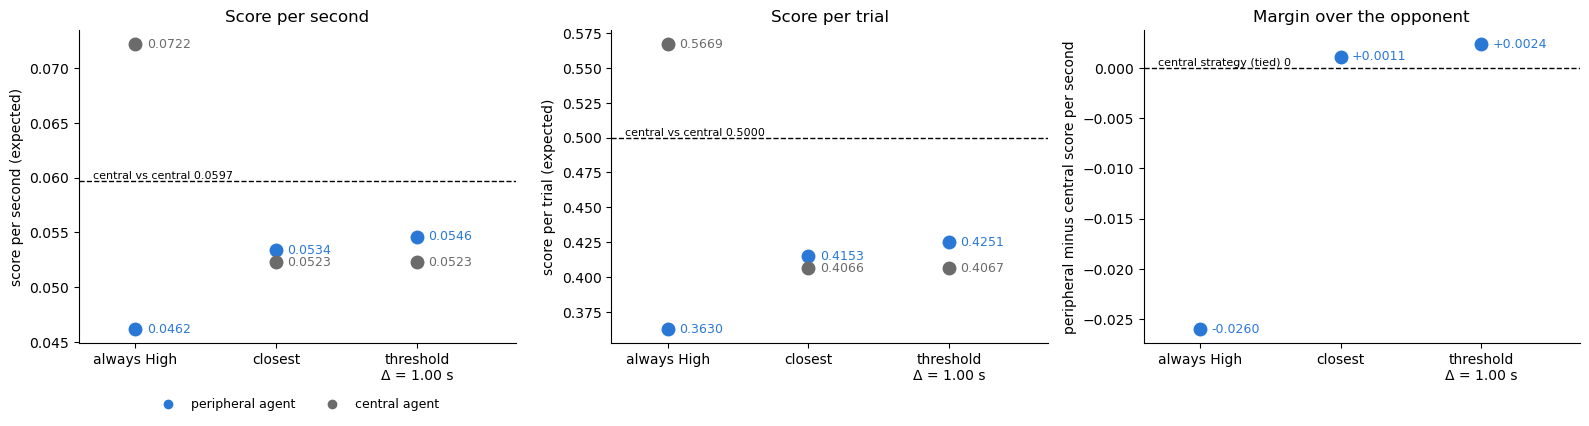

In [6]:
RULES = [('always High', 'high', None), ('closest', 'closest', None), (f'threshold\nΔ = {D_BEST:.2f} s', 'threshold', D_BEST)]
rules = pd.concat([ar.summarise(pooled, OVERHEAD, pol, d).assign(rule=lab) for lab, pol, d in RULES],
                  ignore_index=True)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for ax, (p, c, ylab, r) in zip(axes[:2], (('periph_score_s', 'central_score_s', 'score per second', ref['score_s']),
                                      ('periph_score_trial', 'central_score_trial', 'score per trial', ref['score_trial']))):
    x = np.arange(len(rules))
    ax.plot(x, rules[p], 'o', color=C_PERIPH, ms=9)
    ax.plot(x, rules[c], 'o', color=C_CENTRAL, ms=9)
    for xi, vp, vc in zip(x, rules[p], rules[c]):
        ax.text(xi + 0.08, vp, f'{vp:.4f}', va='center', fontsize=9, color=C_PERIPH)
        ax.text(xi + 0.08, vc, f'{vc:.4f}', va='center', fontsize=9, color=C_CENTRAL)
    ax.axhline(r, color='black', ls='--', lw=1)
    ax.text(-0.3, r, f'central vs central {r:.4f}', va='bottom', fontsize=8)
    ax.set_xticks(x, rules['rule'])
    ax.set_xlim(-0.4, len(rules) - 0.3)
    ax.set_ylabel(f'{ylab} (expected)')
    ax.spines[['top', 'right']].set_visible(False)
axes[0].plot([], [], 'o', color=C_PERIPH, label='peripheral agent')
axes[0].plot([], [], 'o', color=C_CENTRAL, label='central agent')
axes[0].legend(frameon=False, fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.14), ncol=2)
axes[0].set_title('Score per second')
axes[1].set_title('Score per trial')
# plot the peripheral margin over the opponent, against the central strategy's tie
ax = axes[2]
margin = rules['periph_score_s'] - rules['central_score_s']
x = np.arange(len(rules))
ax.plot(x, margin, 'o', color=C_PERIPH, ms=9)
for xi, v in zip(x, margin):
    ax.text(xi + 0.08, v, f'{v:+.4f}', va='center', fontsize=9, color=C_PERIPH)
ax.axhline(0, color='black', ls='--', lw=1)
ax.text(-0.3, 0, 'central strategy (tied) 0', va='bottom', fontsize=8)
ax.set_xticks(x, rules['rule'])
ax.set_xlim(-0.4, len(rules) - 0.3)
ax.set_ylabel('peripheral minus central score per second')
ax.spines[['top', 'right']].set_visible(False)
ax.set_title('Margin over the opponent')
plt.tight_layout(); plt.show()

## 6. The three rules for each set of start positions

**Motivation.** The model is one rule set, but its peripheral start positions come from six trained peripheral models, which wait in slightly different places. The pooled result could hide such differences, so this section repeats section 5 for each set of start positions.

**How to read the figure.** One column per set of start positions (labelled by the trained model they come from). Dots are the peripheral agent's score per second under each rule (colours in the legend). The grey crosses are the central opponent's score when the peripheral agent plays "always High" and "threshold" (central behaviour is the same in both). The dashed line is central vs central, the fixed reference.

**Why it is plotted.** If the dots line up across sets, the result depends on where peripheral agents wait in general, not on any one set.

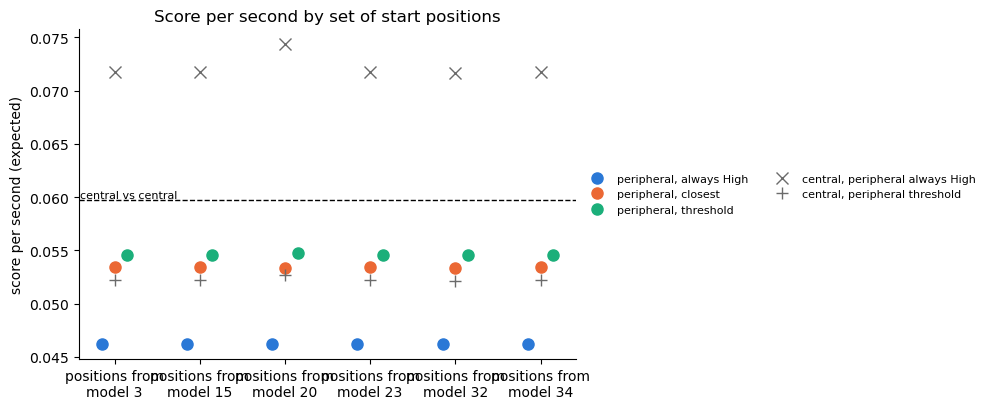

In [7]:
per_model = pd.concat([ar.summarise(races, OVERHEAD, pol, d).assign(rule=lab.split('\n')[0]) for lab, pol, d in RULES],
                      ignore_index=True)

fig, ax = plt.subplots(figsize=(10, 4.2))
models = sorted(per_model['group'].unique())
for k, (rule, col) in enumerate(zip(('always High', 'closest', 'threshold'), (C_HIGH, C_CLOSEST, C_THRESH))):
    s = per_model[per_model['rule'] == rule].set_index('group').loc[models]
    ax.plot(np.arange(len(models)) + (k - 1) * 0.15, s['periph_score_s'], 'o', color=col, ms=8, label=f'peripheral, {rule}')
for rule, mk in (('always High', 'x'), ('threshold', '+')):
    s = per_model[per_model['rule'] == rule].set_index('group').loc[models]
    ax.plot(np.arange(len(models)), s['central_score_s'], mk, color=C_CENTRAL, ms=9, label=f'central, peripheral {rule}')
ax.axhline(ref['score_s'], color='black', ls='--', lw=1)
ax.text(-0.4, ref['score_s'], 'central vs central', ha='left', va='bottom', fontsize=8)
ax.set_xticks(np.arange(len(models)), [f'positions from\nmodel {m}' for m in models])
ax.set_ylabel('score per second (expected)')
ax.legend(frameon=False, fontsize=8, ncol=2, loc='center left', bbox_to_anchor=(1.0, 0.5))
ax.spines[['top', 'right']].set_visible(False)
ax.set_title('Score per second by set of start positions')
plt.tight_layout(); plt.show()

## 7. Central agents turning to face High (logs)

**Motivation.** The next version of the model gives the central agent its ray sensor. It must turn to face High before travelling straight to it, and it can close on High while turning once High is in view. This section measures how central agents do this in the logs. It sets the model's turning rate and closing speed, and records where the model's turn differs from what agents do.

**Method.** For every agent-trial of five central 260929 models (1, 2, 4, 5, 6; both agents), follow the agent from slice onset until it faces High within ±10°. Agent-trials that never face High before the trigger, or face it at onset, are left out.

**Terms**
- Angle to High (φ): High's bearing from the agent minus its heading at onset, 0-180°.
- Sensed (in view): at least one of the agent's 7 rays (0, ±18.3, ±36.7, ±55° from the heading, first hit only) hits any part of High or its trigger box. This uses `analysis/agent_raycast.py`, the replica of the agents' sensor. From the centre, High is sensed when φ < 77.5° (the ±55° ray reaching High's vertex). In these 260929 logs, player 1's rays are blocked by player 0's body (builds before 261014). This changes sensing at onset in 1.1% of player-1 agent-trials. The model's rays pass through the opponent, as in current builds.
- Turning rate: total heading change, counting back-and-forth, over the time to face High (°/s). The rate while rotating counts only frames where the heading changed by more than 0.5°.
- Short way: the agent's net turn went the shorter way round to High. 0.5 = no better than a random direction.
- Rotating / still time: time in frames with / without a heading change above 0.5°.
- Closing speed: reduction in straight-line distance to High's trigger line in frames with High in view before facing it, over the time in those frames (units/s).

**Choices and assumptions**
- The model's turning rate is the median per-agent-trial turning rate (user's choice). It reflects how fast agents turn while they are turning.
- The model's agent turns straight to High, with no back-and-forth. It turns the short way when High is in view at onset, and in a random direction when it is not (user's choice). The logged short-way bias is likely due to inferring High from the Low wall's position (user). That is not in the model yet.
- The model's agent moves only while High is in view (user's choice), at the median closing speed. Logged agents also move while High is out of view.
- How the closing speed is chosen: for each agent-trial, the distance to High's trigger line closed over the frames with High in view before facing it, divided by the time in those frames. The model uses the median over agent-trials (7.57 units/s).
- Why it is kept although it is below the best the controls allow: a zig-zag of allowed directions could close on High at 9.24-10 units/s (mean 9.46 over a 77.5° turn, panel e). Logged agents lose speed by moving at an angle to High (mostly the forward diagonal on High's side), not by moving slowly. The model looks for the best decisions (which wall, when to switch), and keeps agent-derived turning and movement unless they are clearly too inefficient (user's choice). 7.57 is about 80% of the best, and human players are likely to be less efficient still. Human play is the endpoint the model will be applied to.

**How to read the figure.**
- (a) Turning rate per agent-trial (bars). Lines mark the model's rate (median), the pooled rate while rotating, and the code maximum.
- (b) Short-way share by angle to High at onset (dots, with agent-trial counts), for High not sensed at onset. The dashed line is a random direction (0.5). The square is the share when High is in view at onset.
- (c) Mean time to face High, split into rotating (dark) and still (light), for the logs and the model, with High in view or out of view at onset.
- (d) Mean angle turned to face High. Logs: net angle, and total angle counting back-and-forth. Model: the angle it turns.
- (e) Closing speed per agent-trial (bars). Lines mark the model's value (median), the best a zig-zag of allowed directions allows on average over a 77.5° turn, and full speed (10 units/s). The text gives the mean distance moved, and how much closer to High the agent got, before facing High.
- (f) Mean race time from slice onset to trigger in central-vs-central play (the faster agent): logs, model with turn-then-move, and model with moving while turning. The dashed line is straight travel from the centre with no turn.

**Why it is plotted.** Panels (a) and (e) set the model's two new inputs and show how consistent they are. Panels (b) to (d) show what agents do that the model leaves out (turning toward High more often than chance, turning back and forth, pausing). Panel (f) shows the net effect of these choices on race time.

central_alignment_260929_central5: loaded from cache


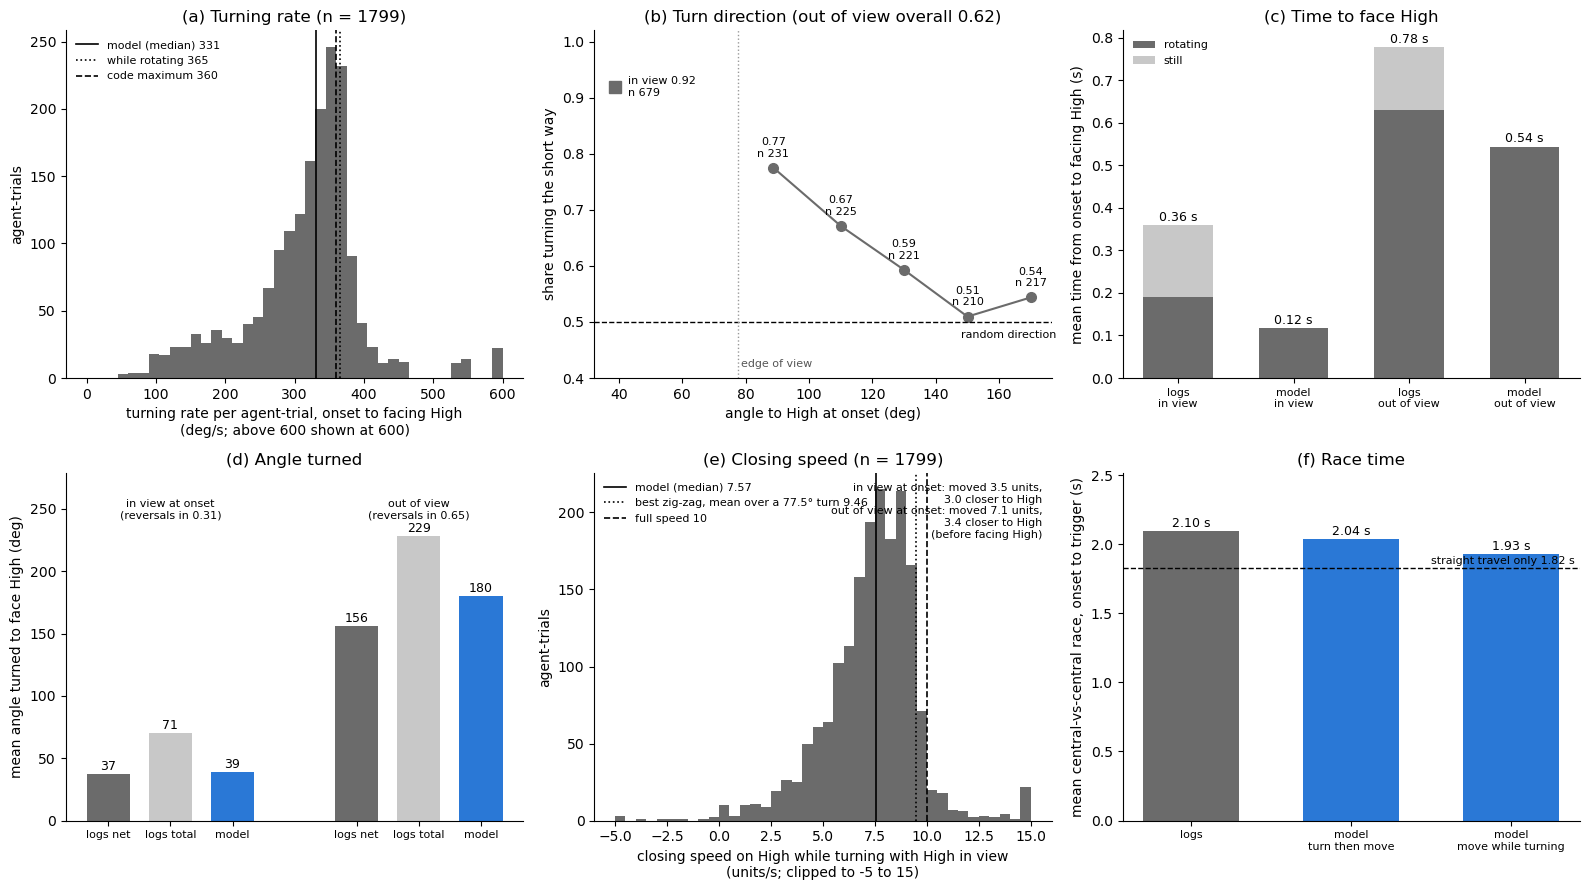

In [8]:
# get how each central agent-trial turns to face High
alignment = data_saving.cached(f'central_alignment_{BATCH}_central5',
                               lambda: ar.collect_central_alignment(SIM_DATA_FOLDER, CENTRAL[:5], verbose=False),
                               recompute=RECOMPUTE, stamp=(tuple(CENTRAL[:5]), ar.ALIGN_TOL, 'rays', 'v4'))
ROT = ar.rotation_speed(alignment)
CLOSE = ar.closing_speed(alignment)
ok = alignment[alignment['t_align'] > 0]
inv, outv = ok[ok['visible']], ok[~ok['visible']]
V = ar.central_visible_half_angle()

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
# (a) turning rate per agent-trial
ax = axes[0, 0]
rate = ok['turned'] / ok['t_align']
ax.hist(rate.clip(upper=600), bins=np.arange(0, 610, 15), color=C_CENTRAL)
rot_pooled = ok['turned'].sum() / ok['t_rotating'].sum()
for v, lab, ls in ((ROT, f'model (median) {ROT:.0f}', '-'), (rot_pooled, f'while rotating {rot_pooled:.0f}', ':'),
                   (360, 'code maximum 360', '--')):
    ax.axvline(v, color='black', ls=ls, lw=1.2, label=lab)
ax.legend(frameon=False, fontsize=8, loc='upper left')
ax.set_xlabel('turning rate per agent-trial, onset to facing High\n(deg/s; above 600 shown at 600)')
ax.set_ylabel('agent-trials')
ax.set_title(f'(a) Turning rate (n = {len(ok)})')

# (b) short-way share by angle to High, out of view
ax = axes[0, 1]
bins = [V, 100, 120, 140, 160, 180]
grp = outv.groupby(pd.cut(outv['phi'].abs(), bins), observed=True)['short_way']
mids = [(a + b) / 2 for a, b in zip(bins[:-1], bins[1:])]
ax.plot(mids, grp.mean().to_numpy(), 'o-', color=C_CENTRAL, ms=7)
for x, m, n_ in zip(mids, grp.mean(), grp.size()):
    ax.text(x, m + 0.02, f'{m:.2f}\nn {n_}', ha='center', fontsize=8)
in_short = inv['short_way'].astype(float).mean()
ax.plot(V / 2, in_short, 's', color=C_CENTRAL, ms=8)
ax.text(V / 2 + 4, in_short, f'in view {in_short:.2f}\nn {len(inv)}', va='center', fontsize=8)
ax.axhline(0.5, color='black', ls='--', lw=1)
ax.text(178, 0.485, 'random direction', ha='right', va='top', fontsize=8)
ax.axvline(V, color='#999999', ls=':', lw=1)
ax.text(V + 1, 0.42, 'edge of view', fontsize=8, color='#555555')
ax.set_ylim(0.4, 1.02)
ax.set_xlabel('angle to High at onset (deg)')
ax.set_ylabel('share turning the short way')
ax.set_title(f"(b) Turn direction (out of view overall {outv['short_way'].astype(float).mean():.2f})")

# (c) time to face High, rotating vs still
ax = axes[0, 2]
model_turn = {'in view': (V / 2) / ROT, 'out of view': 180 / ROT}
labels, rot_t, still_t = [], [], []
for name, g in (('in view', inv), ('out of view', outv)):
    labels += [f'logs\n{name}', f'model\n{name}']
    rot_t += [g['t_rotating'].mean(), model_turn[name]]
    still_t += [g['t_still'].mean(), 0.0]
x = np.arange(len(labels))
ax.bar(x, rot_t, color=C_CENTRAL, width=0.6, label='rotating')
ax.bar(x, still_t, bottom=rot_t, color='#c8c8c8', width=0.6, label='still')
for xi, r_, s_ in zip(x, rot_t, still_t):
    ax.text(xi, r_ + s_ + 0.01, f'{r_ + s_:.2f} s', ha='center', fontsize=9)
ax.set_xticks(x, labels, fontsize=8)
ax.set_ylabel('mean time from onset to facing High (s)')
ax.legend(frameon=False, fontsize=8, loc='upper left')
ax.set_title('(c) Time to face High')

# (d) angle turned
ax = axes[1, 0]
vals = [inv['net_turn'].abs().mean(), inv['turned'].mean(), V / 2,
        outv['net_turn'].abs().mean(), outv['turned'].mean(), 180.0]
labs = ['logs net', 'logs total', 'model', 'logs net', 'logs total', 'model']
xs = np.array([0, 1, 2, 4, 5, 6])
ax.bar(xs, vals, color=[C_CENTRAL, '#c8c8c8', C_PERIPH] * 2, width=0.7)
for xi, v in zip(xs, vals):
    ax.text(xi, v + 3, f'{v:.0f}', ha='center', fontsize=9)
ax.set_xticks(xs, labs, fontsize=8)
ax.text(1, max(vals) * 1.06, f"in view at onset\n(reversals in {(inv['reversals'] > 0).mean():.2f})", ha='center', fontsize=8)
ax.text(5, max(vals) * 1.06, f"out of view\n(reversals in {(outv['reversals'] > 0).mean():.2f})", ha='center', fontsize=8)
ax.set_ylim(0, max(vals) * 1.22)
ax.set_ylabel('mean angle turned to face High (deg)')
ax.set_title('(d) Angle turned')

# (e) closing speed per agent-trial
ax = axes[1, 1]
has_view = ok['t_inview'] > 0
cl = ok.loc[has_view, 'closing_inview'] / ok.loc[has_view, 't_inview']
ax.hist(cl.clip(-5, 15), bins=np.arange(-5, 15.25, 0.5), color=C_CENTRAL)
ax.axvline(CLOSE, color='black', lw=1.2, label=f'model (median) {CLOSE:.2f}')
ZIGZAG_BEST = ar.zigzag_closing_speed(np.linspace(0, V, 10001)).mean()
ax.axvline(ZIGZAG_BEST, color='black', ls=':', lw=1.2, label=f'best zig-zag, mean over a {V:.1f}° turn {ZIGZAG_BEST:.2f}')
ax.axvline(ar.SPEED, color='black', ls='--', lw=1.2, label=f'full speed {ar.SPEED:.0f}')
ax.legend(frameon=False, fontsize=8, loc='upper left')
# note how far agents move before facing High, in view and out of view at onset
ax.text(0.98, 0.97, '\n'.join(f"{n_} at onset: moved {g['path_moved'].mean():.1f} units,\n  {g['closer'].mean():.1f} closer to High"
                              for n_, g in (('in view', inv), ('out of view', outv))) + '\n(before facing High)',
        transform=ax.transAxes, ha='right', va='top', fontsize=8)
ax.set_xlabel('closing speed on High while turning with High in view\n(units/s; clipped to -5 to 15)')
ax.set_ylabel('agent-trials')
ax.set_title(f'(e) Closing speed (n = {len(cl)})')

# (f) central-vs-central race time
ax = axes[1, 2]
race_vals = [timing_df['rt_s'].mean(),
             ar.central_reference(OVERHEAD, central_t=ar.central_times(ROT))['race_s'],
             ar.central_reference(OVERHEAD, central_t=ar.central_times(ROT, close_speed=CLOSE))['race_s']]
labs = ['logs', 'model\nturn then move', 'model\nmove while turning']
ax.bar(range(3), race_vals, color=[C_CENTRAL, C_PERIPH, C_PERIPH], width=0.6)
for xi, v in enumerate(race_vals):
    ax.text(xi, v + 0.03, f'{v:.2f} s', ha='center', fontsize=9)
ax.axhline(ar.TRIGGER_REACH / ar.SPEED, color='black', ls='--', lw=1)
ax.text(2.4, ar.TRIGGER_REACH / ar.SPEED + 0.03, f'straight travel only {ar.TRIGGER_REACH / ar.SPEED:.2f} s', ha='right', fontsize=8)
ax.set_xticks(range(3), labs, fontsize=8)
ax.set_ylim(0, max(race_vals) * 1.2)
ax.set_ylabel('mean central-vs-central race, onset to trigger (s)')
ax.set_title('(f) Race time')
for a_ in axes.ravel():
    a_.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

## 8. Ray-sensing model: the peripheral agent

**Motivation.** Real agents sense walls with 7 rays, and from deep in an alcove the alcove walls block most of them. This version of the model gives both agents that sensor, so the peripheral agent must find a wall before it can head for it. This section shows how the peripheral agent is built, and what sensing costs it on its own.

**The central agent** (inputs from section 7). It waits at the centre with a random heading. If no ray hits High, it turns in a random direction until one does (331°/s), standing still. It then keeps turning until High is straight ahead, closing on High at 7.57 units/s along the straight line (a zig-zag of allowed directions). Then it travels straight at 10 units/s.

**The peripheral agent.**
1. It starts at a logged slice-onset position and heading of a 260929 peripheral model (2,376 agent-trials, models 3, 15, 20, 23, 32, 34). It meets all 40 layouts and both search directions, each equally likely.
2. It senses with the same 7 rays (`analysis/agent_raycast.py`), cast from its current position and heading. Alcove walls block rays; the opponent does not.
3. If its rays do not sense the wall at onset, it moves out of its alcove toward the centre and turns in its search direction at the same time (turning and moving are separate controls), until a ray hits the wall. It then turns the short way onto its path. An agent not starting in an alcove (rare) turns in place. The agent's behaviour depends only on what its rays have sensed, its own position and the arena layout, never on where an unseen wall is.
4. Once the wall is sensed it keeps turning until the first straight stretch of its shortest path is straight ahead, closing along the path at 7.57 units/s. It then follows the path at 10 units/s. At a bend it keeps moving at full speed and turns to face the new stretch at the same time, as turning and moving are separate controls.
5. An agent overlapping a lit trigger at onset wins that wall at once.

**Terms**
- Walls from own alcove: how many walls from the agent's own alcove to the wall in question (0 = own, 1 = adjacent, 4 = opposite).
- Sensed at onset: at least one ray hits the wall (any part of it, or its trigger box) at the onset heading.
- Search: for a wall not sensed at onset, the time from onset until a ray first hits it (s), and how far the agent has moved out by then (units).
- Time to a wall: slice onset to reaching its trigger, for an agent heading there from the start ("High, always" applied to that wall).

**Choices and assumptions** are listed with their sources in `READMEs/analytical_modelling_notes.md` (P1-P17).

**How to read the figure.**
- (a) to (c) are one logged peripheral agent in two example layouts. The grey outline is the arena walls, with High in red and Low in blue. The black square is the agent's onset position. Thin lines are its 7 rays, each drawn to its first hit.
  - (a) Rays at onset, for a layout with High adjacent and Low three walls away. The rays reach Low but not High.
  - (b) The route of "High, always" in the same layout: moving out while turning (dashed), the point where High is first sensed (dot, with the rays at that moment), then the path to High (solid).
  - (c) A layout with High two walls away and Low adjacent. The grey dashed line is the "High, always" route. The star marks where both walls are known and Low is nearer, with the rays at that moment. The blue line is the "nearest" route to Low from there.
- (d) Share of agent-trials whose rays sense a wall at onset, by how many walls it is from the agent's own alcove.
- (e) For walls not sensed at onset, the mean search time (bars), by walls from own alcove. The label gives the mean search time and the mean distance moved out by then.
- (f) Mean time to a wall from onset, with ray sensing (bars) and in the first model where the wall is known at onset (dots), by walls from own alcove. The dashed line is the central agent's mean time to High with rays.

**Why it is plotted.** (a) to (c) show the agent's design on real cases. (d) to (f) show which walls are hidden from the alcove and how much time finding them costs. Walls the peripheral agent could reach first are the near ones, so a cost there matters most.

agent_trajectories_260929_peripheral: loaded from cache
periph_ray_races_260929: loaded from cache


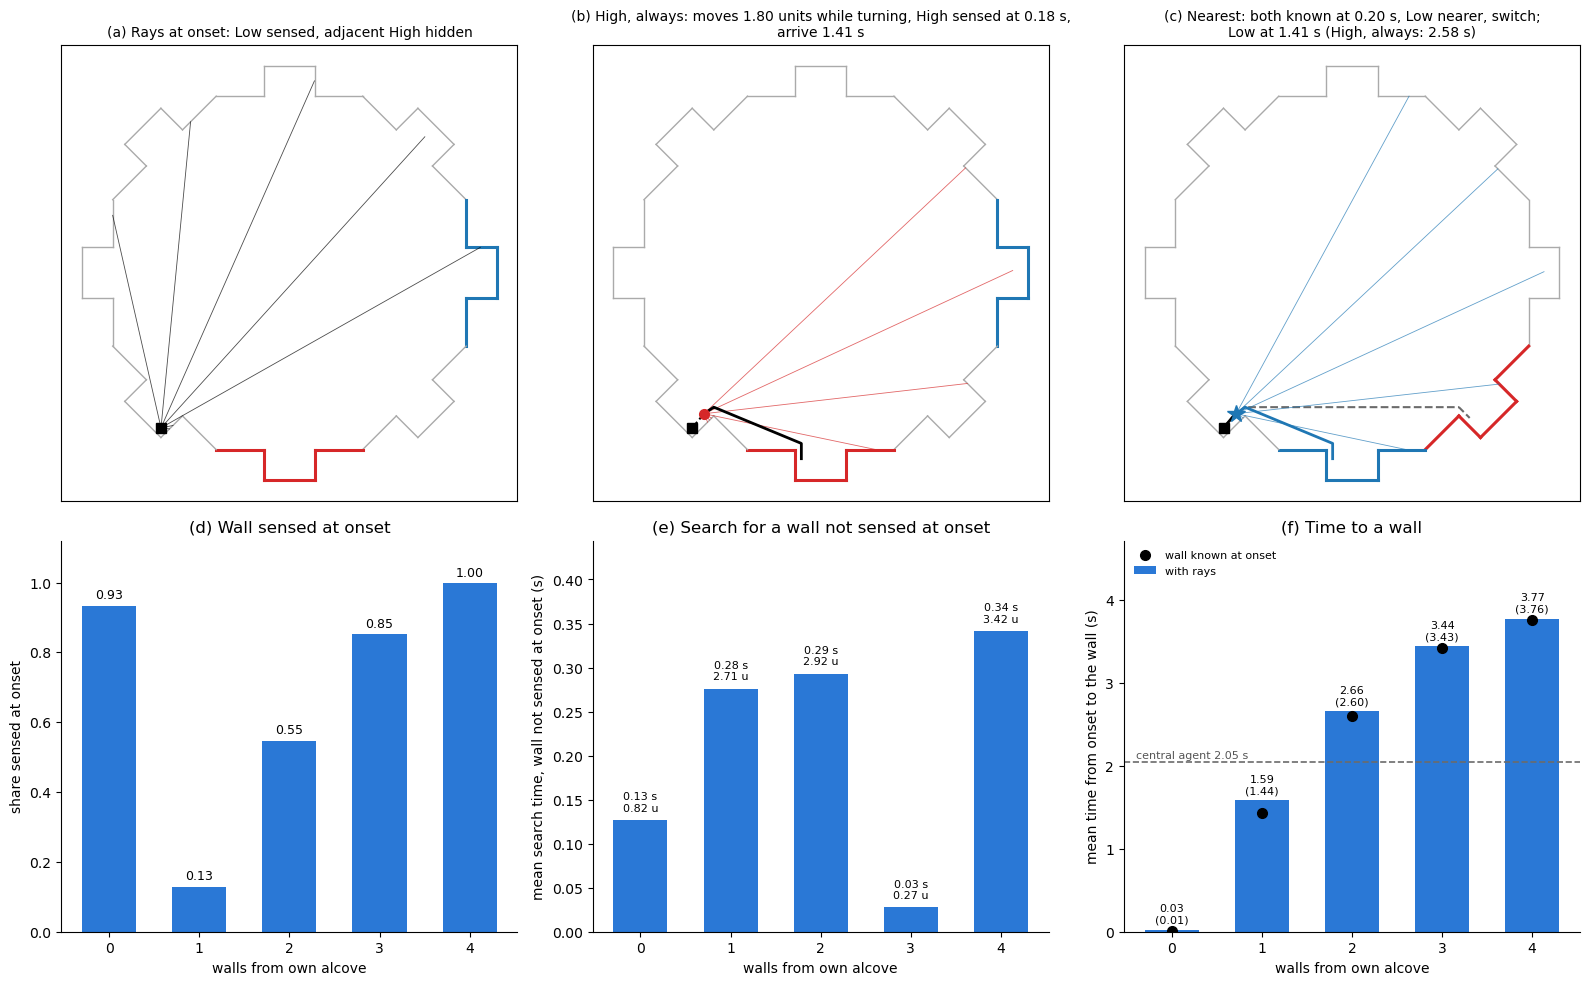

In [9]:
import analysis.agent_loser_choice as lc
import analysis.agent_raycast as agent_raycast
import trajectory_analysis.visibility_occlusion as vo

# get each peripheral agent-trial's logged onset heading (the trajectories cached by the 260929 notebook)
traj = data_saving.cached(f'agent_trajectories_{BATCH}_peripheral',
                          lambda: lc.collect_trajectories(SIM_DATA_FOLDER, PERIPHERAL, verbose=False),
                          recompute=RECOMPUTE, stamp=tuple(PERIPHERAL))
onset = periph.merge(traj[['model', 'trial_num', 'player', 'yaw']], on=['model', 'trial_num', 'player'])
assert len(onset) == len(periph)
pos_r = onset[['x', 'z']].to_numpy(float)
head_r = np.degrees([y[0] for y in onset['yaw']])

# build the ray-sensing races for every position, layout and search direction (a few minutes uncached, over
# ar.N_JOBS worker processes). The search settings are the model defaults: an agent whose target is not sensed
# at onset moves out of its alcove while turning (MOVE_OUT), stepping and turning together (MERGE_STEP)
MERGE_STEP, MOVE_OUT = True, True
ray_races = data_saving.cached(f'periph_ray_races_{BATCH}',
                               lambda: ar.build_races_rays(pos_r, head_r, ROT, CLOSE, groups=onset['model'].to_numpy(),
                                                           merge_step=MERGE_STEP, move_out=MOVE_OUT),
                               recompute=RECOMPUTE,
                               stamp=(tuple(PERIPHERAL), len(pos_r), round(ROT, 3), round(CLOSE, 3), ar.HEAD_STEP, ar.TRACE_DT, MERGE_STEP, MOVE_OUT, 'v10'))
ray_pooled = ray_races.assign(group=0, prob=ray_races['prob'] / ray_races['prob'].sum())
CENTRAL_T = ar.central_times(ROT, close_speed=CLOSE)
REF_RAYS = ar.central_reference(OVERHEAD, central_t=CENTRAL_T)
C_HIGHW, C_LOWW, C_WALL = '#D62728', '#1F77B4', '#AAAAAA'
WALL_SEGS = vo.get_wall_segments()
WALL_IDS = np.repeat(np.arange(ar.NUM_WALLS), 5)


def draw_arena(ax, high, low):
    """ Draw the arena walls, with High and Low coloured. Takes the axis and the High and Low row indices. """

    for (a, b), w in zip(WALL_SEGS, WALL_IDS):
        col = C_HIGHW if w == high else C_LOWW if w == low else C_WALL
        ax.plot([a[0], b[0]], [a[1], b[1]], color=col, lw=2.2 if col != C_WALL else 1)
    ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([])


def draw_rays(ax, q, h, color='black'):
    """ Draw the 7 rays from a position to their first hit. Takes the axis, position, heading (deg) and colour. """

    _, _, dist = agent_raycast.cast_rays(q[None], np.radians([h]))
    dirs = agent_raycast.ray_directions(np.radians([h]))[0]
    for dvec, dd in zip(dirs, dist[0]):
        ax.plot([q[0], q[0] + dd * dvec[0]], [q[1], q[1] + dd * dvec[1]], color=color, lw=0.6, alpha=0.7)


def route(trace, t0=0.0, t1=None, n=200):
    """ Return positions along a traced route between two times. Takes a high_trace result and the times. """

    t1 = trace['arrive'] if t1 is None else t1
    return np.array([trace['state'](t)[0] for t in np.linspace(t0, t1, n)])


# pick the example agent-trial: the first one with a hidden adjacent High that needs a step and Low three walls away sensed
cand = ray_races[(ray_races['high_off'].abs() == 1) & (ray_races['low_off'].abs() == 3) & ray_races['low_sensed0']
                 & (ray_races['high_step'] > 0) & (ray_races['direction'] == 1) & (ray_races['t_high'] > 0)]
ex = cand.iloc[0]
q0, h0 = pos_r[int(ex['pos'])], head_r[int(ex['pos'])]
# pick a layout for the same agent-trial where "nearest" switches to an adjacent Low with High two walls away
same = ray_races[(ray_races['pos'] == ex['pos']) & ray_races['nearest_low'] & (ray_races['high_off'].abs() == 2)
                 & (ray_races['low_off'].abs() == 1)]
ex2 = same.iloc[0]

fig = plt.figure(figsize=(16, 10))
gs = fig.add_gridspec(2, 3, height_ratios=[1.25, 1])
# (a) rays at onset
ax = fig.add_subplot(gs[0, 0])
draw_arena(ax, int(ex['high']), int(ex['low']))
draw_rays(ax, q0, h0)
ax.plot(*q0, 'ks', ms=7)
ax.set_title('(a) Rays at onset: Low sensed, adjacent High hidden', fontsize=10)
# (b) "High, always" route
ax = fig.add_subplot(gs[0, 1])
draw_arena(ax, int(ex['high']), int(ex['low']))
tr = ar.high_trace(q0, h0, int(ex['high']), 1, ROT, CLOSE, merge_step=MERGE_STEP, move_out=MOVE_OUT)
moved = np.linalg.norm(tr['state'](tr['sensed'])[0] - q0)
ax.plot(*route(tr, 0, tr['sensed'], 20).T, color='black', ls='--', lw=1.5)
qs, hs = tr['state'](tr['sensed'])
draw_rays(ax, qs, hs, color=C_HIGHW)
ax.plot(*route(tr, tr['sensed']).T, color='black', lw=2)
ax.plot(*q0, 'ks', ms=7); ax.plot(*qs, 'o', color=C_HIGHW, ms=7)
ax.set_title(f"(b) High, always: moves {moved:.2f} units while turning, High sensed at {tr['sensed']:.2f} s,\n"
             f"arrive {tr['arrive']:.2f} s", fontsize=10)
# (c) "nearest" switch
ax = fig.add_subplot(gs[0, 2])
draw_arena(ax, int(ex2['high']), int(ex2['low']))
tr2 = ar.high_trace(q0, h0, int(ex2['high']), int(ex2['direction']), ROT, CLOSE, merge_step=MERGE_STEP, move_out=MOVE_OUT)
first = ar.trace_first_sensed(tr2)
t_dec = max(tr2['sensed'], first[int(ex2['low'])])
qd, hd_ = tr2['state'](t_dec)
ax.plot(*route(tr2).T, color=C_CENTRAL, ls='--', lw=1.5)
ax.plot(*route(tr2, 0, t_dec).T, color='black', lw=2)
draw_rays(ax, qd, hd_, color=C_LOWW)
to_low = ar.path_points(qd, int(ex2['low']))
ax.plot(to_low[:, 0], to_low[:, 1], color=C_LOWW, lw=2)
ax.plot(*q0, 'ks', ms=7); ax.plot(*qd, '*', color=C_LOWW, ms=13)
ax.set_title(f"(c) Nearest: both known at {t_dec:.2f} s, Low nearer, switch;\n"
             f"Low at {ex2['t_nearest']:.2f} s (High, always: {ex2['t_high']:.2f} s)", fontsize=10)

# (d)-(f) by walls from own alcove, every agent-trial weighted equally
starts_in_alcove = np.array([ar.in_alcove(q) for q in pos_r])
per_wall = ray_pooled.assign(off=ray_pooled['high_off'].abs(), in_alcove=starts_in_alcove[ray_pooled['pos'].to_numpy()])
by_off = per_wall.groupby('off').apply(lambda g: pd.Series(dict(
    sensed0=np.average(g['high_sensed0'], weights=g['prob']),
    search_s=np.average(g.loc[~g['high_sensed0'], 'high_tsense'], weights=g.loc[~g['high_sensed0'], 'prob'])
    if (~g['high_sensed0']).any() else 0.0,
    moved=np.average(np.minimum(g.loc[~g['high_sensed0'], 'high_tsense'] * ar.SPEED, ar.MAX_STEP)
                     * g.loc[~g['high_sensed0'], 'in_alcove'], weights=g.loc[~g['high_sensed0'], 'prob'])
    if (~g['high_sensed0']).any() else 0.0,
    t_rays=np.average(g['t_high'], weights=g['prob']))), include_groups=False)
geo = ar.build_races(pos_r)
by_off['t_geometry'] = geo.assign(off=geo['high_off'].abs()).groupby('off').apply(
    lambda g: np.average(g['t_high'], weights=g['prob']), include_groups=False)
x = by_off.index.to_numpy()
ax = fig.add_subplot(gs[1, 0])
ax.bar(x, by_off['sensed0'], color=C_PERIPH, width=0.6)
for xi, v in zip(x, by_off['sensed0']):
    ax.text(xi, v + 0.02, f'{v:.2f}', ha='center', fontsize=9)
ax.set_ylim(0, 1.12); ax.set_xlabel('walls from own alcove'); ax.set_ylabel('share sensed at onset')
ax.set_title('(d) Wall sensed at onset')
ax = fig.add_subplot(gs[1, 1])
ax.bar(x, by_off['search_s'], color=C_PERIPH, width=0.6)
for xi, v, m_ in zip(x, by_off['search_s'], by_off['moved']):
    ax.text(xi, v + 0.01, f'{v:.2f} s\n{m_:.2f} u', ha='center', fontsize=8)
ax.set_ylim(0, by_off['search_s'].max() * 1.3); ax.set_xlabel('walls from own alcove')
ax.set_ylabel('mean search time, wall not sensed at onset (s)')
ax.set_title('(e) Search for a wall not sensed at onset')
ax = fig.add_subplot(gs[1, 2])
ax.bar(x, by_off['t_rays'], color=C_PERIPH, width=0.6, label='with rays')
ax.plot(x, by_off['t_geometry'], 'o', color='black', ms=7, label='wall known at onset')
for xi, v, g_ in zip(x, by_off['t_rays'], by_off['t_geometry']):
    ax.text(xi, v + 0.08, f'{v:.2f}\n({g_:.2f})', ha='center', fontsize=8)
ax.axhline(CENTRAL_T.mean(), color=C_CENTRAL, ls='--', lw=1.2)
ax.text(-0.4, CENTRAL_T.mean() + 0.05, f'central agent {CENTRAL_T.mean():.2f} s', fontsize=8, color='#555555')
ax.set_ylim(0, by_off['t_rays'].max() * 1.25)
ax.set_xlabel('walls from own alcove'); ax.set_ylabel('mean time from onset to the wall (s)')
ax.legend(frameon=False, fontsize=8, loc='upper left')
ax.set_title('(f) Time to a wall')
for a_ in fig.axes[3:]:
    a_.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

## 9. Ray-sensing model: three peripheral rules

**Motivation.** With rays, the peripheral agent may know only one lit wall when it has to act, so the first model's rules (closest, threshold) no longer apply. This section compares three rules that only use what the agent has sensed, each against the same central agent.

**The rules** (user's choice).
1. **High, always.** Search for High, then go to it.
2. **Low, if Low seen first, else High.** Go to Low if a ray hits Low strictly before High. Both sensed at the same moment (e.g. both at onset) goes High. If neither is sensed at onset, the agent moves out while turning, and the first lit wall a ray hits decides.
3. **Nearest, once both are sensed.** Behave as "High, always" until both walls have been sensed. Then go to the wall with the shorter remaining path from where the agent is at that moment (equal paths go High). If Low is never sensed before High is reached, it reaches High.

**Method.** Score every position, layout and search direction under each rule against the central agent's distribution of times (section 8), as in sections 4-5.

**Terms**
- Score per second, score per trial, margin over the opponent and central vs central: as in sections 4-5, with both agents using rays. Central vs central here has both central agents turning with rays.
- Win share: share of trials the peripheral agent reaches a lit wall first.
- Share heading Low: share of trials in which the rule sends the agent to Low (instant wins count by the rule's choice).
- Race: mean time from slice onset to the first trigger (s).
- Expected score per trial in a layout: win probability × wall value (1.0 High, 0.4 Low), averaged over positions and search directions.

**How to read the table.** One row per rule, then central vs central. Columns as in the terms above. The margin is peripheral minus central score per second.

**How to read the figures.**
- Figure 9a: one column per rule. Blue dots are the peripheral agent and grey dots the central agent, each labelled. Left: score per second, with central vs central dashed. Middle: score per trial. Right: peripheral margin over the central agent, with 0 (a central player against the same opponent) dashed.
- Figure 9b: one panel per rule. Each cell is a layout, by how many walls High (x) and Low (y) are from the agent's own alcove. The number and shading are the peripheral agent's expected score per trial in that layout. Empty cells are layouts that do not occur (Low 1, 2 or 4 walls from High).
- Figure 9c: one column per set of start positions (from each peripheral model), dots for the three rules (colours in the legend). The dashed line is central vs central.

**Why it is plotted.** 9a answers which rule scores best against a central agent, and whether any closes the gap to central play. 9b shows in which layouts each rule gains or loses, and so why. 9c checks that the result holds for every set of waiting positions.

,peripheral score/s,central score/s,margin (score/s),peripheral score/trial,central score/trial,peripheral win share,share heading Low,race (s)
rule,,,,,,,,
"High, always",0.0444,0.0717,-0.0272,0.3559,0.5740,0.4260,0.0000,1.4647
Low if seen first,0.0286,0.0844,-0.0558,0.2305,0.6809,0.3191,0.3065,1.5209
Nearest once both sensed,0.0502,0.0577,-0.0075,0.3984,0.4579,0.5421,0.4253,1.3970
central vs central,0.0590,0.0590,0.0000,0.5000,0.5000,0.5000,0.0000,1.9275


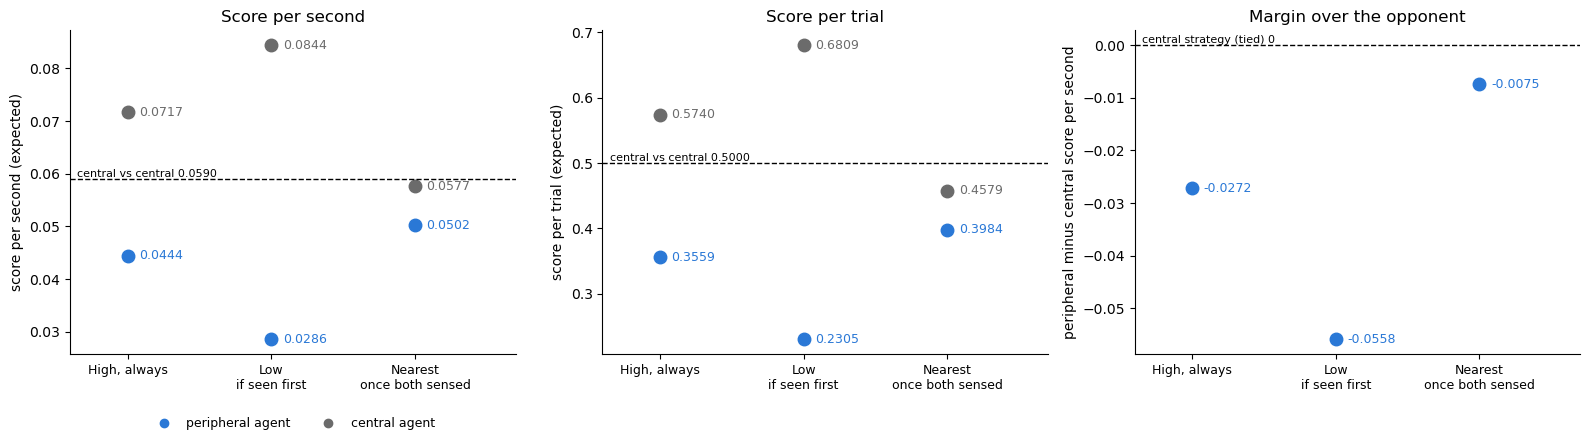

In [10]:
RULES_RAYS = [('High, always', 'high'), ('Low if seen first', 'low_first'), ('Nearest once both sensed', 'nearest')]
C_RULE = {'high': C_HIGH, 'low_first': C_CLOSEST, 'nearest': C_THRESH}
summ_rays = pd.concat([ar.summarise(ray_pooled, OVERHEAD, pol, central_t=CENTRAL_T).assign(rule=lab)
                       for lab, pol in RULES_RAYS], ignore_index=True).set_index('rule')
summ_rays['margin'] = summ_rays['periph_score_s'] - summ_rays['central_score_s']
table = summ_rays[['periph_score_s', 'central_score_s', 'margin', 'periph_score_trial', 'central_score_trial',
                   'periph_win', 'p_go_low', 'race_s']].copy()
table.loc['central vs central'] = [REF_RAYS['score_s'], REF_RAYS['score_s'], 0.0, 0.5, 0.5, 0.5, 0.0, REF_RAYS['race_s']]
table.columns = ['peripheral score/s', 'central score/s', 'margin (score/s)', 'peripheral score/trial',
                 'central score/trial', 'peripheral win share', 'share heading Low', 'race (s)']
display(table.round(4))

# figure 9a: the three rules side by side
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
xr = np.arange(len(summ_rays))
for ax, (pc, cc, ylab, r) in zip(axes[:2], (('periph_score_s', 'central_score_s', 'score per second', REF_RAYS['score_s']),
                                            ('periph_score_trial', 'central_score_trial', 'score per trial', 0.5))):
    ax.plot(xr, summ_rays[pc], 'o', color=C_PERIPH, ms=9)
    ax.plot(xr, summ_rays[cc], 'o', color=C_CENTRAL, ms=9)
    for xi, vp, vc in zip(xr, summ_rays[pc], summ_rays[cc]):
        ax.text(xi + 0.08, vp, f'{vp:.4f}', va='center', fontsize=9, color=C_PERIPH)
        ax.text(xi + 0.08, vc, f'{vc:.4f}', va='center', fontsize=9, color=C_CENTRAL)
    ax.axhline(r, color='black', ls='--', lw=1)
    ax.text(-0.35, r, f'central vs central {r:.4f}', va='bottom', fontsize=8)
    ax.set_ylabel(f'{ylab} (expected)')
ax = axes[2]
ax.plot(xr, summ_rays['margin'], 'o', color=C_PERIPH, ms=9)
for xi, v in zip(xr, summ_rays['margin']):
    ax.text(xi + 0.08, v, f'{v:+.4f}', va='center', fontsize=9, color=C_PERIPH)
ax.axhline(0, color='black', ls='--', lw=1)
ax.text(-0.35, 0, 'central strategy (tied) 0', va='bottom', fontsize=8)
ax.set_ylabel('peripheral minus central score per second')
for ax, t in zip(axes, ('Score per second', 'Score per trial', 'Margin over the opponent')):
    ax.set_xticks(xr, [lab.replace(' once', '\nonce').replace(' if', '\nif') for lab, _ in RULES_RAYS], fontsize=9)
    ax.set_xlim(-0.4, len(xr) - 0.3)
    ax.spines[['top', 'right']].set_visible(False)
    ax.set_title(t)
axes[0].plot([], [], 'o', color=C_PERIPH, label='peripheral agent')
axes[0].plot([], [], 'o', color=C_CENTRAL, label='central agent')
axes[0].legend(frameon=False, fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.16), ncol=2)
plt.tight_layout(); plt.show()

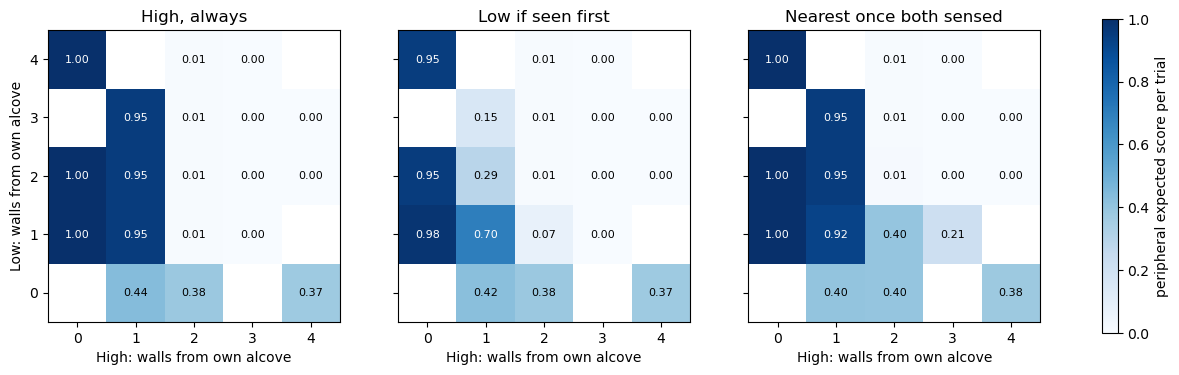

score change per trial in layout  layout share  contribution per trial
Low walls away High walls away                                                                        
1              2                                           0.389         0.062                   0.024
               3                                           0.214         0.094                   0.020
0              1                                          -0.035         0.062                  -0.002
1              1                                          -0.028         0.031                  -0.001
0              2                                           0.018         0.031                   0.001
2              3                                           0.003         0.062                   0.000

In [11]:
# figure 9b: expected peripheral score per trial in each layout, under each rule
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
cells = {}
for ax, (lab, pol) in zip(axes, RULES_RAYS):
    ev = ar.evaluate(ray_pooled, pol, central_t=CENTRAL_T)
    g = pd.DataFrame(dict(h=ray_pooled['high_off'].abs(), l=ray_pooled['low_off'].abs(), w=ray_pooled['prob'],
                          sc=ev['periph_score']))
    grid = g.groupby(['l', 'h']).apply(lambda x: np.average(x['sc'], weights=x['w']), include_groups=False).unstack()
    grid = grid.reindex(index=range(5), columns=range(5))
    cells[pol] = grid
    im = ax.imshow(grid.to_numpy(), origin='lower', cmap='Blues', vmin=0, vmax=1)
    for (li, hi), v in np.ndenumerate(grid.to_numpy()):
        if np.isfinite(v):
            ax.text(hi, li, f'{v:.2f}', ha='center', va='center', fontsize=8, color='white' if v > 0.6 else 'black')
    ax.set_xticks(range(5)); ax.set_yticks(range(5))
    ax.set_xlabel('High: walls from own alcove')
    ax.set_title(lab)
axes[0].set_ylabel('Low: walls from own alcove')
fig.colorbar(im, ax=axes, label='peripheral expected score per trial', shrink=0.85)
plt.show()

# list the layouts where "nearest" changes the score most, against "High, always"
w_lay = ray_pooled.assign(h=ray_pooled['high_off'].abs(), l=ray_pooled['low_off'].abs()).groupby(['h', 'l'])['prob'].sum()
diff = (cells['nearest'] - cells['high']).stack().rename('score change per trial in layout').to_frame()
diff.index = diff.index.rename(['Low walls away', 'High walls away'])
diff['layout share'] = [w_lay.get((h, l), 0.0) for l, h in diff.index]
diff['contribution per trial'] = diff['score change per trial in layout'] * diff['layout share']
display(diff[diff['layout share'] > 0.01].sort_values('contribution per trial', key=abs, ascending=False).head(6).round(3))

**How to read the last table.** One row per layout (walls from own alcove for High and Low), the six layouts where "nearest" changes the peripheral score per trial most against "High, always". The contribution is the change in that layout times the layout's share of trials; contributions add up to the overall change in score per trial.

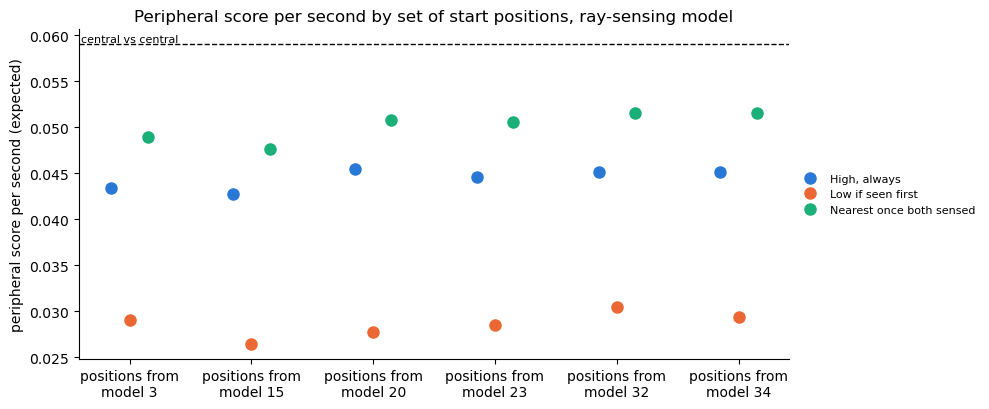

peripheral score per second by model:


rule,high,low_first,nearest
group,,,
3,0.0434,0.0290,0.0489
15,0.0428,0.0264,0.0476
20,0.0455,0.0278,0.0507
23,0.0446,0.0284,0.0506
32,0.0451,0.0305,0.0516
34,0.0452,0.0294,0.0516


In [12]:
# figure 9c: the three rules for each peripheral model
per_model_rays = pd.concat([ar.summarise(ray_races, OVERHEAD, pol, central_t=CENTRAL_T).assign(rule=pol)
                            for _, pol in RULES_RAYS], ignore_index=True)
fig, ax = plt.subplots(figsize=(10, 4.2))
models = sorted(per_model_rays['group'].unique())
for k, (lab, pol) in enumerate(RULES_RAYS):
    sm = per_model_rays[per_model_rays['rule'] == pol].set_index('group').loc[models]
    ax.plot(np.arange(len(models)) + (k - 1) * 0.15, sm['periph_score_s'], 'o', color=C_RULE[pol], ms=8, label=lab)
ax.axhline(REF_RAYS['score_s'], color='black', ls='--', lw=1)
ax.text(-0.4, REF_RAYS['score_s'], 'central vs central', va='bottom', fontsize=8)
ax.set_xticks(np.arange(len(models)), [f'positions from\nmodel {m}' for m in models])
ax.set_ylabel('peripheral score per second (expected)')
ax.legend(frameon=False, fontsize=8, loc='center left', bbox_to_anchor=(1.0, 0.5))
ax.spines[['top', 'right']].set_visible(False)
ax.set_title('Peripheral score per second by set of start positions, ray-sensing model')
plt.tight_layout(); plt.show()
print('peripheral score per second by model:')
display(per_model_rays.pivot(index='group', columns='rule', values='periph_score_s')[[p for _, p in RULES_RAYS]].round(4))

## 10. Why "closest" falls behind once walls must be found

**Motivation.** In the first model, taking the closest wall put the peripheral agent slightly ahead of the central agent. With ray sensing, "nearest, once both are sensed" (the same choice, made once both walls are known) is well behind. This section finds which part of the ray model causes the drop.

**Method.** Start from "closest" with both walls known at onset, then add the ray model's parts one at a time. The central agent is the ray-sensing one in every step.
- Step 0: walls known at onset, the agent sets off along its path at once (the first model's "closest").
- Step 1: as step 0, but the agent first turns to face its path (closing at 7.57 units/s meanwhile).
- Step 2: the same choice as step 0 (closest by path at onset), but the agent must find the chosen wall with its rays (search turn, and a step out if needed), as in section 8.
- Step 3: "nearest, once both are sensed" (section 9).

**Terms.** As in section 9. Change is the step's change in peripheral score per second. In the second table, the chosen wall's distance is in walls from the agent's own alcove; times are the mean time to the chosen wall, with the wall known at onset (step 1) and found with rays (step 2); score change is that row's share of the step 1 to step 2 change in peripheral score per trial.

**How to read the tables.** First table: one row per step, read top to bottom; the row where the score falls most is the cause. Second table: one row per distance of the chosen wall (instant wins left out), showing where the step 2 loss falls. Third table: peripheral score per second under each rule and at step 2, for three versions of the search. (1) The agent steps out only if no heading from where it stands would sense the wall, then searches. (2) The same, but stepping and turning together. (3) The current model: whenever the wall is not sensed at onset, the agent moves out of its alcove while turning. Versions 1 and 2 decide whether to step using where the unseen wall is, which the agent cannot know; version 3 does not.

In [13]:
# get each position's path lengths and the time to every wall when all walls are known at onset
D_known, T_known = data_saving.cached(f'periph_known_wall_times_{BATCH}',
                                      lambda: ar.known_wall_times(pos_r, head_r, ROT, CLOSE),
                                      recompute=RECOMPUTE, stamp=(len(pos_r), round(ROT, 3), round(CLOSE, 3), 'v1'))
pi_, hi_, lo_ = ray_pooled['pos'].to_numpy(), ray_pooled['high'].to_numpy(), ray_pooled['low'].to_numpy()
closest_path = D_known[pi_, lo_] < D_known[pi_, hi_] - 1e-9


def score_step(t_high, t_low, go_low):
    """ Return the summary for given peripheral times and choices. Takes times to High and Low and the Low choices. """

    r = ray_pooled.assign(t_high=t_high, t_low=t_low, low_first=go_low)
    return ar.summarise(r, OVERHEAD, 'low_first', central_t=CENTRAL_T).iloc[0], ar.evaluate(r, 'low_first', central_t=CENTRAL_T)


steps = {'0 walls known, sets off at once': score_step(D_known[pi_, hi_] / ar.SPEED, D_known[pi_, lo_] / ar.SPEED, closest_path),
         '1 + turns to face its path': score_step(T_known[pi_, hi_], T_known[pi_, lo_], closest_path),
         '2 + finds the chosen wall with rays': score_step(ray_pooled['t_high'], ray_pooled['t_low'], closest_path)}
steps['3 nearest, once both sensed'] = (ar.summarise(ray_pooled, OVERHEAD, 'nearest', central_t=CENTRAL_T).iloc[0], None)
breakdown = pd.DataFrame({k: v[0] for k, v in steps.items()}).T[['periph_score_s', 'central_score_s', 'periph_score_trial', 'periph_win']]
breakdown['margin'] = breakdown['periph_score_s'] - breakdown['central_score_s']
breakdown['change'] = breakdown['periph_score_s'].astype(float).diff()
breakdown.columns = ['peripheral score/s', 'central score/s', 'peripheral score/trial', 'peripheral win share', 'margin', 'change']
display(breakdown.astype(float).round(4))

# show where the step 2 loss falls, by how far the chosen wall is from the agent's own alcove
e1, e2 = steps['1 + turns to face its path'][1], steps['2 + finds the chosen wall with rays'][1]
inst = ((ray_pooled['t_high'] == 0) | (ray_pooled['t_low'] == 0)).to_numpy()
w_ = ray_pooled['prob'].to_numpy()
by_chosen = pd.DataFrame(dict(
    off=np.where(closest_path, ray_pooled['low_off'].abs(), ray_pooled['high_off'].abs()), w=w_,
    t1=np.where(closest_path, T_known[pi_, lo_], T_known[pi_, hi_]),
    t2=np.where(closest_path, ray_pooled['t_low'], ray_pooled['t_high']),
    win1=e1['periph_win'], win2=e2['periph_win'], d=e2['periph_score'] - e1['periph_score']))[~inst]
where_lost = by_chosen.groupby('off').apply(lambda g: pd.Series({
    'share of trials': g['w'].sum(),
    'time, wall known (s)': np.average(g['t1'], weights=g['w']), 'time, with rays (s)': np.average(g['t2'], weights=g['w']),
    'win, wall known': np.average(g['win1'], weights=g['w']), 'win, with rays': np.average(g['win2'], weights=g['w']),
    'score change per trial': (g['w'] * g['d']).sum()}), include_groups=False)
where_lost.index.name = 'chosen wall: walls from own alcove'
display(where_lost.round(3))

# compare with the earlier version, where the agent stepped out before searching (saved copy of its cache)
def version_scores(races):
    """ Return peripheral score per second under each rule and at step 2. Takes one version's race rows. """

    pooled = races.assign(group=0, prob=races['prob'] / races['prob'].sum())
    return [ar.summarise(pooled, OVERHEAD, pol, central_t=CENTRAL_T).iloc[0]['periph_score_s'] for _, pol in RULES_RAYS] + \
        [score_step(pooled['t_high'], pooled['t_low'], closest_path)[0]['periph_score_s']]


# compare with the earlier versions of the search (saved copies of their caches)
versions = pd.DataFrame({
    'step out, then search': version_scores(
        data_saving.load_data(f'periph_ray_races_{BATCH}_step_then_search', data_saving.cache_dir)['result']),
    'step out while searching, if needed': version_scores(
        data_saving.load_data(f'periph_ray_races_{BATCH}_step_with_search', data_saving.cache_dir)['result']),
    'move out while searching (current)': version_scores(ray_races)},
    index=[lab for lab, _ in RULES_RAYS] + ['closest, chosen wall found with rays (step 2)'])
versions.index.name = 'peripheral score per second'
display(versions.round(4))

periph_known_wall_times_260929: loaded from cache


,peripheral score/s,central score/s,peripheral score/trial,peripheral win share,margin,change
"0 walls known, sets off at once",0.0531,0.0513,0.4175,0.5965,0.0018,NaN
1 + turns to face its path,0.0530,0.0513,0.4171,0.5959,0.0017,-0.0001
2 + finds the chosen wall with rays,0.0513,0.0529,0.4067,0.5810,-0.0015,-0.0016
"3 nearest, once both sensed",0.0502,0.0577,0.3984,0.5421,-0.0075,-0.0012


,share of trials,"time, wall known (s)","time, with rays (s)","win, wall known","win, with rays",score change per trial
chosen wall: walls from own alcove,,,,,,
0,0.017,0.180,0.382,1.000,1.000,0.00
1,0.344,1.451,1.581,0.999,0.956,-0.01
2,0.250,2.601,2.647,0.010,0.009,-0.00
3,0.156,3.429,3.430,0.000,0.000,0.00


,"step out, then search","step out while searching, if needed",move out while searching (current)
peripheral score per second,,,
"High, always",0.0394,0.0438,0.0444
Low if seen first,0.0264,0.0282,0.0286
Nearest once both sensed,0.0447,0.0494,0.0502
"closest, chosen wall found with rays (step 2)",0.0444,0.0505,0.0513


## 11. Inference of where High is

**Motivation.** Without inference, an agent that has not sensed High turns in a random direction. But what it has sensed narrows down where High can be, so it could turn the way High more probably lies.

**Method.** At onset, every wall a ray hits is known to be High, Low or unlit. The agent combines this with the layout rules (High uniform; Low 1, 2 or 4 walls from High) to get each wall's probability of being High (`ar.high_posterior_given`). If High is not sensed, it turns in the direction with the lower expected time until a ray first hits High, using the arena map to time each candidate wall. It decides once, at onset; a tie is 50/50. Both agents can infer; the opponent's position is not used. For the peripheral agent this reweights the two search directions of each race; for the central agent it gives one time distribution per Low position.

**Terms.** Search time: onset until a ray first hits High, for agents that do not sense it at onset (s). Margin: peripheral minus central score per second, as in section 9.

**How to read the tables.** First table: mean time with and without inference, for the peripheral agent's search for a hidden High and for the central agent's time to High. Second table: margin for each peripheral rule (rows) with neither agent, only one, or both agents inferring (columns).

In [14]:
# get the inferring central agent's times (by Low position) and reweight the peripheral search directions
CENTRAL_T_INF = ar.central_times_inferred(ROT, CLOSE)
ray_inf = ar.infer_direction(ray_races, ar.onset_sensed(pos_r, head_r))
inf_pooled = ray_inf.assign(group=0, prob=ray_inf['prob'] / ray_inf['prob'].sum())
w_low = ar.low_offset_weights()
hidden = ~ray_pooled['high_sensed0']
search = pd.DataFrame({
    'without inference': [np.average(ray_pooled.loc[hidden, 'high_tsense'], weights=ray_pooled.loc[hidden, 'prob']),
                          CENTRAL_T.mean()],
    'with inference': [np.average(inf_pooled.loc[hidden, 'high_tsense'], weights=inf_pooled.loc[hidden, 'prob']),
                       sum(w_low[k] * CENTRAL_T_INF[k].mean() for k in CENTRAL_T_INF)]},
    index=['peripheral: search time for a hidden High (s)', 'central: time to High (s)'])
display(search.round(3))

settings = {'neither infers': (ray_pooled, CENTRAL_T), 'only central infers': (ray_pooled, CENTRAL_T_INF),
            'only peripheral infers': (inf_pooled, CENTRAL_T), 'both infer': (inf_pooled, CENTRAL_T_INF)}
margins = pd.DataFrame({name: [ar.summarise(r, OVERHEAD, pol, central_t=ct).iloc[0][['periph_score_s', 'central_score_s']]
                               .pipe(lambda x: x['periph_score_s'] - x['central_score_s']) for _, pol in RULES_RAYS]
                        for name, (r, ct) in settings.items()}, index=[lab for lab, _ in RULES_RAYS])
margins.index.name = 'margin (peripheral - central score/s)'
display(margins.round(4))
print(f"central vs central score per second: {REF_RAYS['score_s']:.4f} without inference, "
      f"{ar.central_reference(OVERHEAD, central_t=CENTRAL_T_INF)['score_s']:.4f} with")

,without inference,with inference
peripheral: search time for a hidden High (s),0.254,0.148
central: time to High (s),2.046,2.030


,neither infers,only central infers,only peripheral infers,both infer
margin (peripheral - central score/s),,,,
"High, always",-0.0272,-0.0274,-0.0273,-0.0275
Low if seen first,-0.0558,-0.0560,-0.0600,-0.0602
Nearest once both sensed,-0.0075,-0.0077,-0.0075,-0.0077


central vs central score per second: 0.0590 without inference, 0.0591 with


## 12. The Δ rule with inference about both walls

**Motivation.** In the first model the best rule was a threshold: go High unless it is more than Δ seconds further than Low. With rays the agent may not know where one or both walls are, so the rule must work from what it has sensed, using inference to judge an unseen wall.

**Method** (rule agreed with the user, `delta2`).
1. At onset and whenever a ray first hits a new wall, the agent works out where both walls could be: the layout rules, conditioned on every wall sensed so far (`ar.joint_posterior`).
2. It goes for Low if (distance to High - distance to Low) / 10 units/s > Δ, otherwise High. A sensed wall's distance is its shortest path; an unseen wall's is its expected path over where it could be.
3. If the chosen wall is sensed it goes to it. If not, it searches for it: moves out of its alcove while turning, in the direction that should find that wall sooner.
4. It re-decides at every new wall and may switch either way.
5. Backpedal. If the agent is in its own alcove but off its trigger, and the chance that its chosen wall is its own wall is at least 0.8, it backs straight into the trigger at full speed without turning. Inference is enough; it need not see the wall, so turning to look would only cost time. The 0.8 is an arbitrary value picked for now (user's choice).
6. The agent knows a wall only from experience or inference. A ray hit is experience. So is standing on its own trigger at onset without the trial ending, which shows its own wall is unlit. This is treated like a ray hit on that wall, even when no ray reaches it.
7. Δ is swept from 0 to 3.8 s. Each race stores its outcome as a function of Δ, so every Δ is scored exactly from one build.

An earlier version inferred only where High was and always steered by High; it is shown dashed for comparison. It missed the layouts where High is far and in view and an adjacent Low is hidden by the alcove, because it never considered where an unseen Low was.

**Terms.** Δ: how much further High may be than Low, in seconds of travel, before the agent goes for Low. Other terms as in section 9.

**Choices.** Both agents infer their search direction (section 11). The expected distance to an unseen wall leaves out the time needed to find it, as searching is short (section 11) and the user chose distance for this reason.

**How to read the figure.** x is Δ in both panels. Left: peripheral (blue) and central (grey) score per second with the current rule; the dashed blue line is the High-only version. The black dashed line is central vs central. The dotted vertical line marks the best Δ, and the grey band the range within 0.5% of it. Right: the peripheral margin over the central agent for both versions; the dashed line at 0 is a central player against the same opponent.

**Why it is plotted.** The sweep shows which Δ is best, how sharply the score depends on it, and what inferring Low adds.

**How to read the tables.** First: each rule's scores, with each Δ rule at its own best Δ. "Ends at Low" counts instant Low wins for every rule. Second: Δ chosen on five sets of start positions (from five peripheral models) and scored on the sixth, beside that set's own best. Third: the races changed by the backpedal and own-trigger experience (method steps 5-6), at the best Δ, against the saved version without them. Rows split by what is at the agent's own wall; values are summed over all trials, so they add to the change in the overall means.

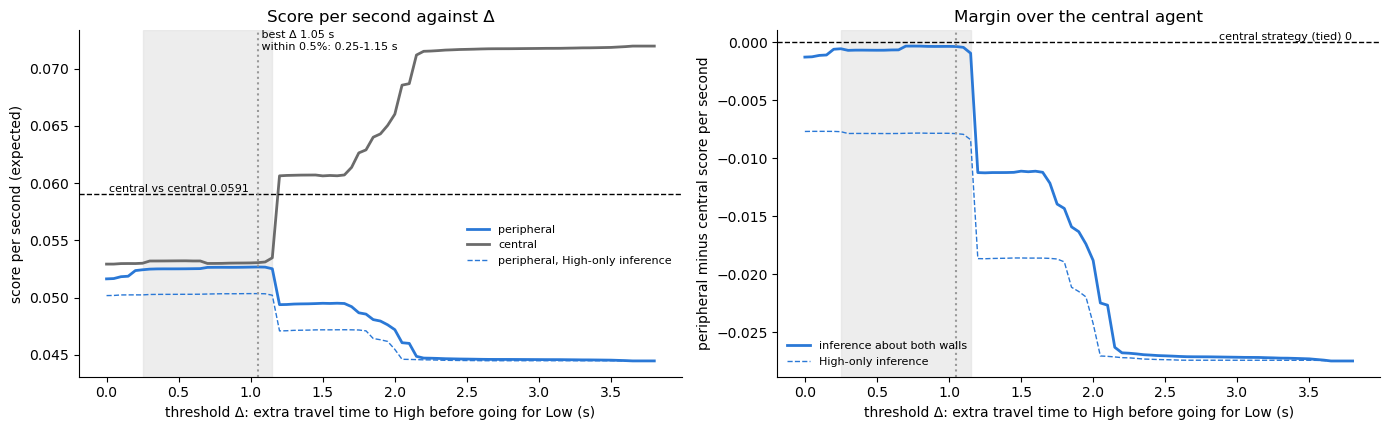

,peripheral score/s,central score/s,margin,peripheral score/trial,peripheral win share,ends at Low
"High, always",0.0445,0.0720,-0.0275,0.3552,0.4252,0.1167
Nearest once both sensed,0.0502,0.0579,-0.0077,0.3974,0.5417,0.4262
"Δ rule, High-only inference (Δ 1.00 s)",0.0503,0.0582,-0.0079,0.3988,0.5390,0.2645
"Δ rule, inference about both walls (Δ 1.05 s)",0.0527,0.0531,-0.0004,0.4157,0.5813,0.3091
central vs central,0.0591,0.0591,0.0000,0.5000,0.5000,0.0000


,Δ chosen on the others,score at that Δ,best score for this set,its own best Δ,margin at chosen Δ
start positions from model,,,,,
3,1.05,0.0504,0.0504,0.70,-0.0049
15,1.05,0.0501,0.0501,0.70,-0.0055
20,0.80,0.0544,0.0546,1.05,0.0031
23,1.05,0.0534,0.0534,0.70,0.0012
32,1.05,0.0538,0.0538,0.70,0.0020
34,1.05,0.0538,0.0538,0.85,0.0020


,share of trials,"race time change (s, per trial)",peripheral score change (per trial),share where the peripheral score falls
own wall,,,,
High,0.00506,-0.00098,0.00000,0.00000
Low,0.00484,-0.00095,-0.00016,0.00026
unlit,0.00005,-0.00000,0.00000,0.00000
all changed races,0.00996,-0.00193,-0.00016,0.00026


peripheral score/s 0.05268 before, 0.05267 with the backpedal; central 0.05304 before, 0.05305 with


In [15]:
D_GRID = np.round(np.arange(0, 3.81, 0.05), 2)


def delta_sweep(pooled, ct, policy):
    """ Return peripheral and central scores for every Δ on the grid. Takes pooled races, central times and the Δ policy. """

    rows = []
    for dl in D_GRID:
        r = ar.summarise(pooled, OVERHEAD, policy, dl, central_t=ct).iloc[0]
        rows.append(dict(delta=dl, periph=r['periph_score_s'], central=r['central_score_s']))
    out = pd.DataFrame(rows)
    out['margin'] = out['periph'] - out['central']
    return out


sw_both = delta_sweep(ray_pooled, CENTRAL_T_INF, 'delta2')        # chooses its own search directions
sw_high = delta_sweep(inf_pooled, CENTRAL_T_INF, 'delta')         # High-only version
D_BEST_RAYS = float(sw_both.loc[sw_both['periph'].idxmax(), 'delta'])
D_BEST_HIGH = float(sw_high.loc[sw_high['periph'].idxmax(), 'delta'])
top_rays = sw_both.loc[sw_both['periph'] >= 0.995 * sw_both['periph'].max(), 'delta']
REF_INF = ar.central_reference(OVERHEAD, central_t=CENTRAL_T_INF)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
ax = axes[0]
ax.plot(sw_both['delta'], sw_both['periph'], color=C_PERIPH, lw=2, label='peripheral')
ax.plot(sw_both['delta'], sw_both['central'], color=C_CENTRAL, lw=2, label='central')
ax.plot(sw_high['delta'], sw_high['periph'], color=C_PERIPH, lw=1, ls='--', label='peripheral, High-only inference')
ax.axhline(REF_INF['score_s'], color='black', ls='--', lw=1)
ax.text(0.02, REF_INF['score_s'], f"central vs central {REF_INF['score_s']:.4f}", ha='left', va='bottom', fontsize=8)
ax.set_ylabel('score per second (expected)')
ax.legend(frameon=False, fontsize=8, loc='center right', bbox_to_anchor=(1.0, 0.38))
ax = axes[1]
ax.plot(sw_both['delta'], sw_both['margin'], color=C_PERIPH, lw=2, label='inference about both walls')
ax.plot(sw_high['delta'], sw_high['margin'], color=C_PERIPH, lw=1, ls='--', label='High-only inference')
ax.axhline(0, color='black', ls='--', lw=1)
ax.text(3.8, 0, 'central strategy (tied) 0', ha='right', va='bottom', fontsize=8)
ax.set_ylabel('peripheral minus central score per second')
ax.legend(frameon=False, fontsize=8, loc='lower left')
for ax in axes:
    ax.axvspan(top_rays.min(), top_rays.max(), color='#dddddd', alpha=0.5)
    ax.axvline(D_BEST_RAYS, color='#999999', ls=':', lw=1.5)
    ax.set_xlabel('threshold Δ: extra travel time to High before going for Low (s)')
    ax.spines[['top', 'right']].set_visible(False)
axes[0].text(D_BEST_RAYS, axes[0].get_ylim()[1], f" best Δ {D_BEST_RAYS:.2f} s\n within 0.5%: {top_rays.min():.2f}-{top_rays.max():.2f} s",
             va='top', fontsize=8)
axes[0].set_title('Score per second against Δ')
axes[1].set_title('Margin over the central agent')
plt.tight_layout(); plt.show()


def rule_row(rows, policy, delta=None):
    """ Return one rule's scores, with "ends at Low" counting instant Low wins. Takes pooled rows, the policy and its Δ. """

    r = ar.summarise(rows, OVERHEAD, policy, delta, central_t=CENTRAL_T_INF).iloc[0]
    ev = ar.evaluate(rows, policy, delta, central_t=CENTRAL_T_INF)
    inst_high, inst_low = (rows['t_high'] == 0).to_numpy(), ((rows['t_low'] == 0) & (rows['t_high'] > 0)).to_numpy()
    low = np.where(inst_high, False, np.where(inst_low, True, ev['go_low'].to_numpy()))
    return pd.Series({'peripheral score/s': r['periph_score_s'], 'central score/s': r['central_score_s'],
                      'margin': r['periph_score_s'] - r['central_score_s'], 'peripheral score/trial': r['periph_score_trial'],
                      'peripheral win share': r['periph_win'], 'ends at Low': float((rows['prob'] * low).sum())})


rules_tab = pd.DataFrame({'High, always': rule_row(inf_pooled, 'high'),
                          'Nearest once both sensed': rule_row(inf_pooled, 'nearest'),
                          f'Δ rule, High-only inference (Δ {D_BEST_HIGH:.2f} s)': rule_row(inf_pooled, 'delta', D_BEST_HIGH),
                          f'Δ rule, inference about both walls (Δ {D_BEST_RAYS:.2f} s)': rule_row(ray_pooled, 'delta2', D_BEST_RAYS)}).T
rules_tab.loc['central vs central'] = [REF_INF['score_s'], REF_INF['score_s'], 0.0, 0.5, 0.5, 0.0]
display(rules_tab.round(4))

# check the choice of Δ: choose it on five sets of start positions, score it on the sixth
per_set = pd.concat([ar.summarise(ray_races, OVERHEAD, 'delta2', d, CENTRAL_T_INF).assign(delta=d) for d in D_GRID], ignore_index=True)
loo = []
for m_ in sorted(ray_races['group'].unique()):
    train = per_set[per_set['group'] != m_].groupby('delta')['periph_score_s'].mean()
    d_tr = float(train.idxmax())
    test = per_set[per_set['group'] == m_].set_index('delta')
    loo.append({'start positions from model': m_, 'Δ chosen on the others': d_tr, 'score at that Δ': test.loc[d_tr, 'periph_score_s'],
                'best score for this set': test['periph_score_s'].max(), 'its own best Δ': float(test['periph_score_s'].idxmax()),
                'margin at chosen Δ': test.loc[d_tr, 'periph_score_s'] - test.loc[d_tr, 'central_score_s']})
display(pd.DataFrame(loo).set_index('start positions from model').round(4))

# compare with the rule before the backpedal and own-trigger experience were added (saved copy of its cache)
pre = data_saving.load_data(f'periph_ray_races_{BATCH}_v8', data_saving.cache_dir)['result']
e_pre = ar.evaluate(pre, 'delta2', D_BEST_RAYS, CENTRAL_T_INF)
e_now = ar.evaluate(ray_races, 'delta2', D_BEST_RAYS, CENTRAL_T_INF)
w_ = (ray_races['prob'] / ray_races['prob'].sum()).to_numpy()
d_score = (e_now['periph_score'] - e_pre['periph_score']).to_numpy()
d_race = (e_now['race_s'] - e_pre['race_s']).to_numpy()
changed = (np.abs(d_score) > 1e-9) | (np.abs(d_race) > 1e-9)
own_wall = np.where(ray_races['high_off'] == 0, 'High', np.where(ray_races['low_off'] == 0, 'Low', 'unlit'))
bp = pd.DataFrame({'own wall': own_wall, 'share of trials': w_, 'race time change (s, per trial)': w_ * d_race,
                   'peripheral score change (per trial)': w_ * d_score,
                   'share where the peripheral score falls': w_ * (d_score < -1e-9)})[changed]
bp = bp.groupby('own wall').sum()
bp.loc['all changed races'] = bp.sum()
display(bp.round(5))
before = ar.summarise(pre.assign(group=0, prob=pre['prob'] / pre['prob'].sum()), OVERHEAD, 'delta2', D_BEST_RAYS, central_t=CENTRAL_T_INF).iloc[0]
print(f"peripheral score/s {before['periph_score_s']:.5f} before, {rules_tab.iloc[3]['peripheral score/s']:.5f} with the backpedal; "
      f"central {before['central_score_s']:.5f} before, {rules_tab.iloc[3]['central score/s']:.5f} with")

## 13. Where the score comes from

**Motivation.** With the Δ rule the peripheral agent wins more races than the central agent but scores about the same. This section shows which layouts each agent wins, at which wall, and how the routes look in each kind of layout.

**Method.** Use the Δ rule with inference about both walls at its best Δ, against the central agent with inference. Group trials by where High is relative to the peripheral agent's own alcove, and add up each agent's wins and score per trial in each group. Draw example layouts for one peripheral agent at the centre of an alcove back, facing out.

**Terms.**
- Instant: the peripheral agent starts overlapping a lit trigger and wins that wall at once.
- High adjacent / own alcove / 2 or more walls away: where High is, counted from the peripheral agent's own alcove.
- Peripheral wins at High / at Low; central wins (always at High). Shares are of all trials and add to the share of trials in that group.

**How to read the figure.**
- (a)-(d): example layouts. High is red, Low blue. The black square is the peripheral agent (facing out of its alcove), the grey dot the central agent. The black line is the peripheral agent's route: dashed while it searches for an unseen wall, solid once it heads for a sensed one. A star marks a decision (blue: going for Low, red: going for High). The orange line is the central agent's straight route to High after it has turned. Each title gives the peripheral agent's time, the central agent's mean time in that layout, and the share of races the peripheral agent wins there.
- (e): for each group, the share of trials the peripheral agent wins at High (dark blue), wins at Low (light blue), and the central agent wins (grey). Bar height is the group's share of all trials.
- (f): each group's contribution to score per trial, peripheral (blue) and central (grey).
- (g): a hidden adjacent High, found by turning toward it (solid) or away from it (dashed), with the time to High for each and the central agent's mean time.

**Why it is plotted.** (a)-(d) show the routes behind each kind of outcome. (e) and (f) show how often each happens and what it is worth, which is what decides the score. (g) shows why a wrong search direction rarely loses the adjacent race.

**How to read the table.** The same numbers as (e) and (f): one row per group, then the total.

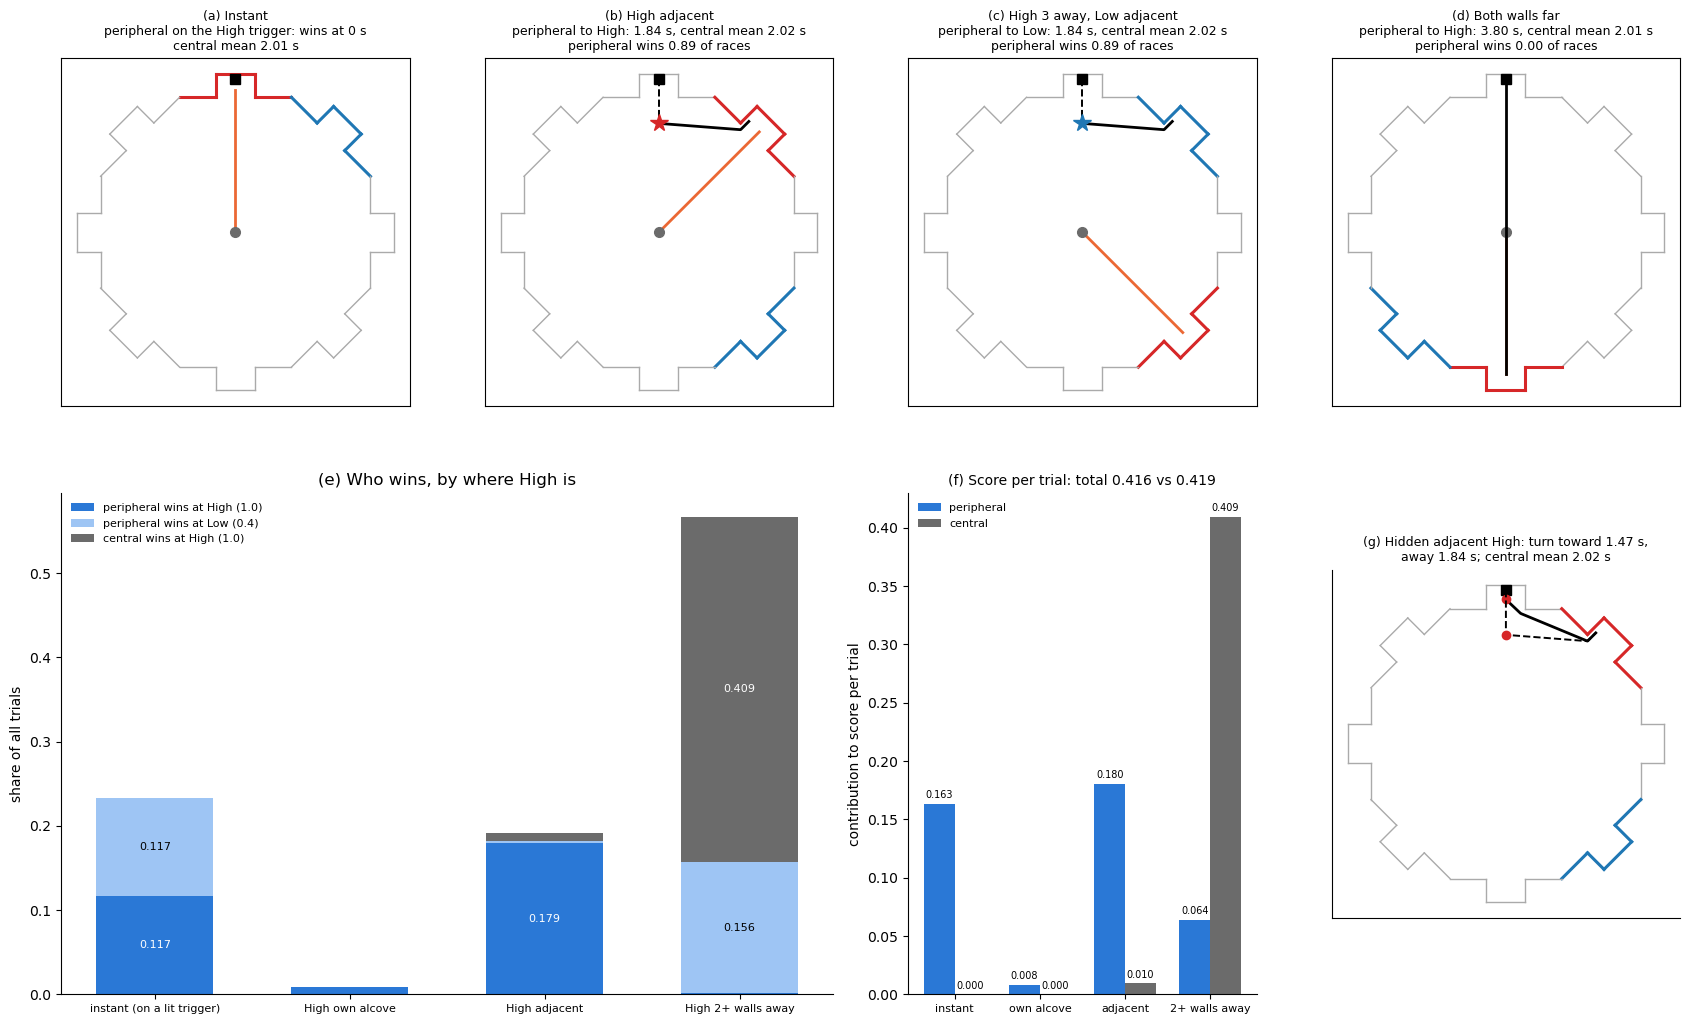

,share of trials,peripheral wins at High,peripheral wins at Low,central wins (High),peripheral score/trial,central score/trial
grp,,,,,,
instant (on a lit trigger),0.233,0.117,0.117,0.000,0.163,0.000
High own alcove,0.008,0.008,0.000,0.000,0.008,0.000
High adjacent,0.192,0.179,0.003,0.010,0.180,0.010
High 2+ walls away,0.567,0.001,0.156,0.409,0.064,0.409
total,1.000,0.305,0.276,0.419,0.416,0.419


In [16]:
# get each race's outcome under the Δ rule at its best Δ, and group by where High is
ev_n = ar.evaluate(ray_pooled, 'delta2', D_BEST_RAYS, central_t=CENTRAL_T_INF)
w_n = ray_pooled['prob'].to_numpy()
inst_n = ((ray_pooled['t_high'] == 0) | (ray_pooled['t_low'] == 0)).to_numpy()
win_n = ev_n['periph_win'].to_numpy()
at_low = np.where((ray_pooled['t_high'] == 0).to_numpy(), False,
                  ev_n['go_low'].to_numpy() | ((ray_pooled['t_low'] == 0) & (ray_pooled['t_high'] > 0)).to_numpy())
GROUPS = ['instant (on a lit trigger)', 'High own alcove', 'High adjacent', 'High 2+ walls away']
grp = np.select([inst_n, ray_pooled['high_off'].abs() == 0, ray_pooled['high_off'].abs() == 1], GROUPS[:3], GROUPS[3])
parts = pd.DataFrame(dict(grp=grp, share=w_n, ph=w_n * win_n * ~at_low, pl=w_n * win_n * at_low, cw=w_n * (1 - win_n)))
outcome = parts.groupby('grp')[['share', 'ph', 'pl', 'cw']].sum().reindex(GROUPS)
outcome['ps'], outcome['cs'] = outcome['ph'] + 0.4 * outcome['pl'], outcome['cw']
outcome.loc['total'] = outcome.sum()
outcome.columns = ['share of trials', 'peripheral wins at High', 'peripheral wins at Low', 'central wins (High)',
                   'peripheral score/trial', 'central score/trial']

# set up the example layouts for one peripheral agent at the back of alcove 0, facing out
BACK, H0 = ar.alcove_back_positions()[0], 180.0
C_ROUTE = '#eb6834'


def central_info(high, low):
    """ Return the central agent's mean time to High in a layout. Takes the High and Low row indices. """

    return CENTRAL_T_INF[(low - high) % ar.NUM_WALLS].mean()


def periph_win_share(t, high, low):
    """ Return the share of races a peripheral time wins against the central times of a layout. """

    return float((CENTRAL_T_INF[(low - high) % ar.NUM_WALLS] > t).mean())


def best_dir(high):
    """ Return the search direction that senses a wall sooner for the example agent. Takes the wall row index. """

    t = [ar.step_search_trace(BACK, H0, d, ROT)['first'][high] for d in (1, -1)]
    return 1 if t[0] <= t[1] else -1


def draw_central(ax, high):
    """ Draw the central agent and its straight route to High. Takes the axis and the High row index. """

    pts = ar.path_points(np.zeros(2), high)
    ax.plot(pts[:, 0], pts[:, 1], color=C_ROUTE, lw=2)
    ax.plot(0, 0, 'o', color=C_CENTRAL, ms=7)


fig = plt.figure(figsize=(17, 11))
gs = fig.add_gridspec(2, 4, height_ratios=[1.15, 1])
examples = [('(a) Instant', 0, 1), ('(b) High adjacent', 1, 3), ('(c) High 3 away, Low adjacent', 3, 1), ('(d) Both walls far', 4, 5)]
for c, (lab, hg, lw) in enumerate(examples):
    ax = fig.add_subplot(gs[0, c])
    draw_arena(ax, hg, lw)
    ax.plot(*BACK, 'ks', ms=7)
    draw_central(ax, hg)
    ct_mean = central_info(hg, lw)
    if hg == 0:
        title = f'{lab}\nperipheral on the High trigger: wins at 0 s\ncentral mean {ct_mean:.2f} s'
    else:
        r = ar.delta2_route(BACK, H0, hg, lw, 1, D_BEST_RAYS, ROT, CLOSE)
        for state, s0, e, t0, is_search in r['segments']:
            xy = np.array([state(t)[0] for t in np.linspace(s0, e, 150)])
            ax.plot(xy[:, 0], xy[:, 1], color='black', lw=1.4 if is_search else 2, ls='--' if is_search else '-')
        for t_d, q, to_low in r['decisions'][1:]:
            ax.plot(*q, '*', color=C_LOWW if to_low else C_HIGHW, ms=13)
        title = (f"{lab}\nperipheral to {'Low' if r['go_low'] else 'High'}: {r['time']:.2f} s, central mean {ct_mean:.2f} s\n"
                 f"peripheral wins {periph_win_share(r['time'], hg, lw):.2f} of races")
    ax.set_title(title, fontsize=9)

# (e) outcomes by group, (f) score by group
og = outcome.loc[GROUPS]
xg = np.arange(len(GROUPS))
ax = fig.add_subplot(gs[1, 0:2])
ax.bar(xg, og['peripheral wins at High'], color='#2a78d6', width=0.6, label='peripheral wins at High (1.0)')
ax.bar(xg, og['peripheral wins at Low'], bottom=og['peripheral wins at High'], color='#9ec5f4', width=0.6, label='peripheral wins at Low (0.4)')
ax.bar(xg, og['central wins (High)'], bottom=og['peripheral wins at High'] + og['peripheral wins at Low'], color=C_CENTRAL,
       width=0.6, label='central wins at High (1.0)')
for xi, (ph, pl, cw) in enumerate(zip(og['peripheral wins at High'], og['peripheral wins at Low'], og['central wins (High)'])):
    for base, v, dark in ((0, ph, True), (ph, pl, False), (ph + pl, cw, True)):
        if v > 0.02:
            ax.text(xi, base + v / 2, f'{v:.3f}', ha='center', va='center', fontsize=8, color='white' if dark else 'black')
ax.set_xticks(xg, GROUPS, fontsize=8)
ax.set_ylabel('share of all trials')
ax.legend(frameon=False, fontsize=8, loc='upper left')
ax.set_title('(e) Who wins, by where High is')
ax = fig.add_subplot(gs[1, 2])
ax.bar(xg - 0.18, og['peripheral score/trial'], width=0.36, color=C_PERIPH, label='peripheral')
ax.bar(xg + 0.18, og['central score/trial'], width=0.36, color=C_CENTRAL, label='central')
for xi, (a_, b_) in enumerate(zip(og['peripheral score/trial'], og['central score/trial'])):
    ax.text(xi - 0.18, a_ + 0.005, f'{a_:.3f}', ha='center', fontsize=7)
    ax.text(xi + 0.18, b_ + 0.005, f'{b_:.3f}', ha='center', fontsize=7)
ax.set_xticks(xg, [g.replace(' (on a lit trigger)', '').replace('High ', '') for g in GROUPS], fontsize=8)
ax.set_ylabel('contribution to score per trial')
ax.legend(frameon=False, fontsize=8)
ax.set_title(f"(f) Score per trial: total {outcome.loc['total', 'peripheral score/trial']:.3f} vs "
             f"{outcome.loc['total', 'central score/trial']:.3f}", fontsize=10)
# (g) hidden adjacent High, turning toward or away
ax = fig.add_subplot(gs[1, 3])
hg, lw = 1, 3
draw_arena(ax, hg, lw)
ax.plot(*BACK, 'ks', ms=7)
good = best_dir(hg)
times = {}
for d, ls in ((good, '-'), (-good, '--')):
    tr = ar.high_trace(BACK, H0, hg, d, ROT, CLOSE)
    ax.plot(*route(tr).T, color='black', lw=2 if ls == '-' else 1.4, ls=ls)
    ax.plot(*tr['state'](tr['sensed'])[0], 'o', color=C_HIGHW, ms=6)
    times[d] = tr['arrive']
ax.set_title(f"(g) Hidden adjacent High: turn toward {times[good]:.2f} s,\naway {times[-good]:.2f} s; "
             f"central mean {central_info(hg, lw):.2f} s", fontsize=9)
for a_ in fig.axes[4:7]:
    a_.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()
display(outcome.round(3))

## Interpretation

**Inputs**
- Every one of the 990 measured trials has a median moving speed of 10.0 units/s (section 1). Path length therefore converts directly to time.
- The overhead is 6.55 s per trial (human social mean), against a race of at most 1.82 s. So score per second is driven mostly by score per trial. The agent trials average 7.09 s, because the simulation rounds each delay up to a 1/3 s frame.

**Where the choice matters (section 3)**
- 0.939 of peripheral onset positions are past the trigger line, mostly at the alcove back.
- Only Low is winnable in 0.219 of position-layouts. This is the score that "always High" leaves behind.
- Both walls are winnable in 0.156. Here, heading Low gives up a High win. Most of these are an adjacent High with the agent close to, but not on, its own Low trigger.
- In the remaining 0.626 (only High winnable 0.219, neither 0.407), the rules can only differ by sending the agent to a losing Low.

**The three rules (sections 4 and 5)**
- **Always High.** Peripheral 0.0462 score/s against central 0.0722 (score per trial 0.363 vs 0.567).
- **Closest.** Peripheral 0.0534 against central 0.0523 (+16% for the peripheral agent). The peripheral agent now out-scores its opponent.
- **Threshold.** The best Δ is 1.00 s, and any Δ from 0.20 to 1.15 s comes within 0.5% of it. It gives peripheral 0.0546 against central 0.0523 (+18% over always High). Score per trial is 0.425 vs 0.407.
- Why the threshold rule beats "closest": below Δ = 0.2 s, the agent gives up winnable Highs that are only slightly further than Low.
- Above Δ = 1.15 s, the agent stops taking the adjacent Low when High is two walls away (a 1.17 s gap). Its score drops to 0.048, and the central agent rises to 0.056.
- Even the best rule leaves the peripheral agent below central-vs-central play (0.0546 vs 0.0597, 91%). Head to head, though, it scores slightly more than the central agent (0.0546 vs 0.0523).

**Relative score (section 5, right panel)**
- Against a central opponent, going central ties (margin 0). Going peripheral gives a margin of +0.0011 per second with "closest" and +0.0024 with the threshold rule. With "always High" the margin is −0.0260.
- Peripheral play with a good wall rule costs the player some of its own score (0.0546 vs 0.0597). It costs the central opponent more (0.0523 vs 0.0597). A player trying to finish ahead of the other player therefore does better peripheral, while a player trying to maximise its own score does better central.
- The margin is small and depends on the wall rule. It is also a geometric upper limit, so visibility may remove it.

**By start positions (section 6).** The model is one rule set; only the peripheral agent's start positions differ, taken from each of the six peripheral models. All six sets give the same scores under each rule (always High 0.046, closest 0.053, threshold 0.055). With start positions from model 20 the central opponent scores more under "always High" (0.0744 vs 0.072 for the others). So in this first model the result depends on the general peripheral waiting position, not on any one set.

**Answer.** On geometry alone, a peripheral agent that keeps going High unless it is about 0.2-1.15 s further than Low scores 18% more per second than one that always goes High. It then out-scores a central opponent. Most of the gain is already captured by simply going to the closest wall (+16%).

**Limits**
- Both agents know both lit walls at onset and move along shortest paths at full speed from onset. Real peripheral agents can't see adjacent walls from the alcove back, so these are upper limits for the peripheral agent.
- The central agent's rule is checked on won trials only.
- The model says nothing yet about how human players choose, or how fast they move.

**Central agents turning to face High (section 7).** These are inputs for the next version of the model, not yet used in sections 3-6.
- Turning rate: median 331°/s per agent-trial (n 1,799). While actually rotating it is 365°/s, at the code maximum of 360°/s. The model uses 331°/s.
- Turn direction (High sensed by the rays or not): with High out of view, agents turn the short way on 0.62 of agent-trials. The share is 0.77 just outside the view (77.5-100°) and 0.51-0.54 when High is behind (140-180°). With High in view it is 0.92. The bias is likely from inferring High from the Low wall's position, which the model adds in section 11.
- Agents take longer to face High than the model's agent: 0.36 s vs 0.12 s with High in view, 0.78 s vs 0.54 s out of view. They turn back and forth (reversals in 0.31 and 0.65 of agent-trials). They turn 71° in total for a net 37° (in view) and 229° for a net 157° (out of view). They also spend 0.17 s and 0.15 s not rotating. Their net turn (157°) is smaller than the model's random-direction turn (180°), but the back-and-forth more than cancels this.
- Agents move while turning. Before facing High they move 3.5 units and get 3.0 closer to High (in view at onset), or 7.1 units and 3.4 closer (out of view). With High in view they close on it at a median 7.57 units/s (full speed 10). The model's agent closes at 7.57 units/s only while High is in view, and stands still while High is out of view.
- The closing speed is kept at the agents' 7.57 units/s, about 80% of the best a zig-zag allows (9.46 units/s, panel e). The model's aim is the best decisions, with agent-like turning and movement, as human players are likely to be less efficient still.
- Net effect on race time: central-vs-central races last 2.10 s in the logs. The model gives 2.04 s with turn-then-move and 1.93 s with moving while turning (straight travel alone 1.82 s). The model's central agent is therefore 0.17 s faster than logged agents, because it turns without back-and-forth or pauses.


**The peripheral agent with rays (section 8)**
- From inside the alcove the agent rarely senses an adjacent wall at onset (0.13), against 0.55 for walls two away, 0.85 for three and 1.00 for the opposite wall.
- When a wall is not sensed at onset, the agent moves out while turning until a ray hits it. For an adjacent wall this takes a mean 0.27 s, by which time it has moved out 2.68 units. For walls two away it takes 0.29 s (2.92 units).
- Finding a wall costs most for the walls the agent can win. Its mean time to an adjacent wall rises from 1.44 s (known at onset) to 1.59 s with rays, against 2.05 s for the central agent to High. For walls two to four away the cost is 0.01-0.06 s, and those are lost anyway.
- In the example (b), the agent moves out 1.80 units while turning, senses the hidden adjacent High at 0.18 s and arrives at 1.41 s. In (c) the same agent, heading for a High two walls away, senses the adjacent Low as it leaves the alcove. Both are known at 0.20 s, Low is nearer, and it reaches Low at 1.41 s, against 2.58 s for High.

**Three peripheral rules with rays (section 9)**
- "Nearest, once both are sensed" scores best: 0.0502 per second, against 0.0444 for "High, always" and 0.0286 for "Low, if seen first". The central agent scores 0.0577, 0.0717 and 0.0844 against them. Central vs central is 0.0590.
- Under "nearest" the peripheral agent wins 0.542 of races and heads for Low in 0.425 of trials, but many of its wins are at Low (worth 0.4). Its score per trial is 0.398 against the central agent's 0.458, so its margin is -0.0075 per second.
- "Nearest" gains in two layouts: Low adjacent with High two walls away (+0.389 per trial in that layout, 0.024 overall) and with High three away (+0.214, 0.020 overall). There the agent leaves the alcove toward a High it cannot win, senses the adjacent Low and switches. It loses a little where it switches away from a winnable adjacent High (-0.035 and -0.028 per trial in those layouts).
- "Low, if seen first" loses because, from the alcove, a far Low is often sensed before a hidden adjacent High. With High adjacent its expected score per trial falls from 0.95 to 0.15 (Low three away) and 0.29 (Low two away).
- All six sets of start positions agree: "nearest" 0.0476-0.0516, "High, always" 0.0428-0.0455, "Low, if seen first" 0.0264-0.0305 per second.
- Against the first model (sections 4-5), ray sensing turns a small lead into a deficit for these rules. There the best rule out-scored the central agent (0.0546 vs 0.0523). Here the best of these three reaches 85% of central-vs-central play (0.0502 vs 0.0590) and stays behind its opponent. Section 12 recovers most of this with inference about both walls.

**Why "closest" falls behind with rays (section 10)**
- Against the same ray-sensing central agent, "closest" with walls known at onset is slightly ahead (step 0, margin +0.0018). Turning to face the path first changes almost nothing (step 1, -0.0001). Having to find the chosen wall with the rays costs 0.0016 per second and puts it slightly behind (step 2, margin -0.0015). Deciding only once both walls are sensed ("nearest", step 3) costs a further 0.0012 (margin -0.0075).
- The cost of finding walls falls on adjacent walls (second table): the time to an adjacent chosen wall rises from 1.45 s to 1.58 s, and its win share falls from 0.999 to 0.956. Walls two or more away were lost anyway. A target in the agent's own alcove that it does not sense at onset is reached more slowly (0.18 s to 0.38 s), as moving out is the wrong way for it, but this is 0.017 of trials and they are still won.
- The step 3 cost is the price of not knowing Low at onset. "Nearest" commits to High first and notices Low only on the way, so some Lows that "closest" would take from the start are reached later or not at all.
- How the agent searches matters (third table). Stepping out before searching gave "nearest" 0.0447; stepping and turning together, only when needed, 0.0494; moving out while turning whenever the wall is not sensed at onset (the current model) 0.0502. The first two decided whether to step from where the unseen wall was, which the agent cannot know; the current rule uses only what it has sensed.
- Inference (section 11) and the Δ rule with inference about both walls (section 12) come next. The central agent's turning is cleaner than logged agents' (section 7f).

**Inference (section 11)**
- Inference shortens searching: the peripheral agent finds a hidden High in 0.148 s instead of 0.254 s, and the central agent reaches High in 2.030 s instead of 2.046 s.
- Used only to choose the search direction, it barely changes the scores. With both agents inferring, the "nearest" margin is -0.0077 against -0.0075 without, and "High, always" -0.0275 against -0.0272. The races the peripheral agent can win are against an adjacent High, which it finds by moving out of the alcove, and from there both adjacent walls come into view at about the same time whichever way it turns.
- "Low, if seen first" gets worse when the peripheral agent infers (-0.0558 to -0.0600): turning toward the likely High often passes Low first, as Low lies next to High, and that rule then takes Low.

**The Δ rule with inference about both walls (section 12)**
- The best threshold is Δ = 1.05 s, and any Δ from 0.25 to 1.15 s comes within 0.5% of it. It gives the peripheral agent 0.0527 per second against the central agent's 0.0531, a margin of -0.0004 (0.7% behind). Central vs central is 0.0591.
- The High-only version reaches only 0.0503 against 0.0582 (margin -0.0079, Δ 1.00 s), about the same as "nearest" (0.0502 against 0.0579). The difference is the inferred, unseen Low: with High seen far away, the agent can judge that Low is probably next to its own alcove and go and look for it.
- Past 1.15 s the score drops in steps, as in the first model, as the agent stops taking an adjacent Low when High is two walls away (a gap of about 1.2 s), and then other Lows.
- Δ is not tuned to particular start positions: chosen on five sets and scored on the sixth, it loses at most 0.0002 (positions from model 20). At the chosen Δ, positions from models 20, 23, 32 and 34 out-score the central opponent (margin +0.0012 to +0.0031) and positions from models 3 and 15 trail (-0.0049 and -0.0055).
- The backpedal and own-trigger experience barely change these results (third table). Races change in 0.0100 of trials. In 0.0099 of trials the own wall is lit (High 0.0051, Low 0.0048) and the agent backs into it. These races end sooner, so race time falls by 0.0019 s per trial over all trials. In 0.00026 of trials (own wall Low) the agent backs into Low where before it turned, saw High and won it, so peripheral score per trial falls by 0.00016. No backpedal at a logged position lost the gamble (own wall unlit). The unlit row (0.00005) is own-trigger experience at the few starts whose rays miss the own wall.
- Net, peripheral score per second goes from 0.05268 to 0.05267 and central from 0.05304 to 0.05305. Nearly all logged agents start on their trigger, so the backpedal rarely applies; it matters for the designed start positions (`peripheral_start_positions.ipynb`).

**Where the score comes from (section 13)**
- The peripheral agent wins more races (0.305 at High + 0.276 at Low = 0.581) than the central agent (0.419), but its Low wins are worth 0.4, so score per trial is close: 0.416 against 0.419.
- It wins nearly every instant layout (0.233 of trials, half at Low) and adjacent-High layout (0.179 of 0.192; example (b), 1.84 s against the central mean 2.02 s).
- High is two or more walls from its alcove in 0.567 of trials. The central agent wins 0.409 of all trials there. The peripheral agent takes 0.156 at Low there, as in example (c), where it sees High far away, infers Low is near, finds it and reaches it in 1.84 s. When both walls are far it loses, as in (d) (3.80 s against 2.01 s).
- A wrong search direction rarely loses the adjacent race: in (g) turning away takes 1.84 s instead of 1.47 s, still ahead of the central agent's mean 2.02 s.

**Limits of the ray-sensing model.** The central agent turns more cleanly than logged agents (its races are 0.17 s shorter, section 7f), and the peripheral agent's search is just as idealised. The central agent always goes High and chooses its search direction once, while the peripheral agent's Δ is tuned and it re-decides at every new wall, so the two are not optimised equally. Neither agent uses the opponent's position. Peripheral start positions come from self-play, where the opponent is also peripheral. The audit of the model is in `READMEs/analytical_modelling_notes.md`; `geometric_model_assembly.ipynb` walks through the final model for reading.